# Brain Walk · Notebook 1 : le prétraitement de l'EEG

PSY2007D — Laboratoire 1, automne 2026

<table style="width:100%; border-collapse:separate; border-spacing:0; margin:6px 0 10px 0;"><tr><td style="background:#0B2545; color:#FFFFFF; padding:10px 14px; border:3px solid #FFFFFF; border-radius:8px; vertical-align:top; width:25%;"><div style="font-size:0.8em; color:#C9D6E8;">NOTEBOOK 1</div><div style="font-weight:bold; font-size:1.05em; color:#FFFFFF;">Prétraitement</div><div style="font-size:0.85em; color:#C9D6E8;">lire · nettoyer · époques</div></td><td style="background:#EEF3F9; color:#0B2545; padding:10px 14px; border:3px solid #FFFFFF; border-radius:8px; vertical-align:top; width:25%;"><div style="font-size:0.8em; color:#5B6472;">NOTEBOOK 2</div><div style="font-weight:bold; font-size:1.05em; color:#0B2545;">ERP</div><div style="font-size:0.85em; color:#5B6472;">P2 · N400 · LPC · hypothèses H1-H10</div></td><td style="background:#EEF3F9; color:#0B2545; padding:10px 14px; border:3px solid #FFFFFF; border-radius:8px; vertical-align:top; width:25%;"><div style="font-size:0.8em; color:#5B6472;">NOTEBOOK 3</div><div style="font-weight:bold; font-size:1.05em; color:#0B2545;">Rythmes</div><div style="font-size:0.85em; color:#5B6472;">spectres · temps-fréquence</div></td><td style="background:#EEF3F9; color:#0B2545; padding:10px 14px; border:3px solid #FFFFFF; border-radius:8px; vertical-align:top; width:25%;"><div style="font-size:0.8em; color:#5B6472;">NOTEBOOK 4</div><div style="font-weight:bold; font-size:1.05em; color:#0B2545;">Apprentissage</div><div style="font-size:0.85em; color:#5B6472;">décoder (facultatif, non noté)</div></td></tr></table>

Le projet **Brain Walk** compare la lecture **assis** et **en marchant**. Ce notebook nettoie l'EEG d'un participant étape par étape,
jusqu'aux **ERP** (potentiels évoqués : la réponse moyenne du cerveau à un type de mot), puis applique la même chaîne à tous. Ses
fichiers (`pretraite_00/`) sont lus par les notebooks 2, 3 et 4.

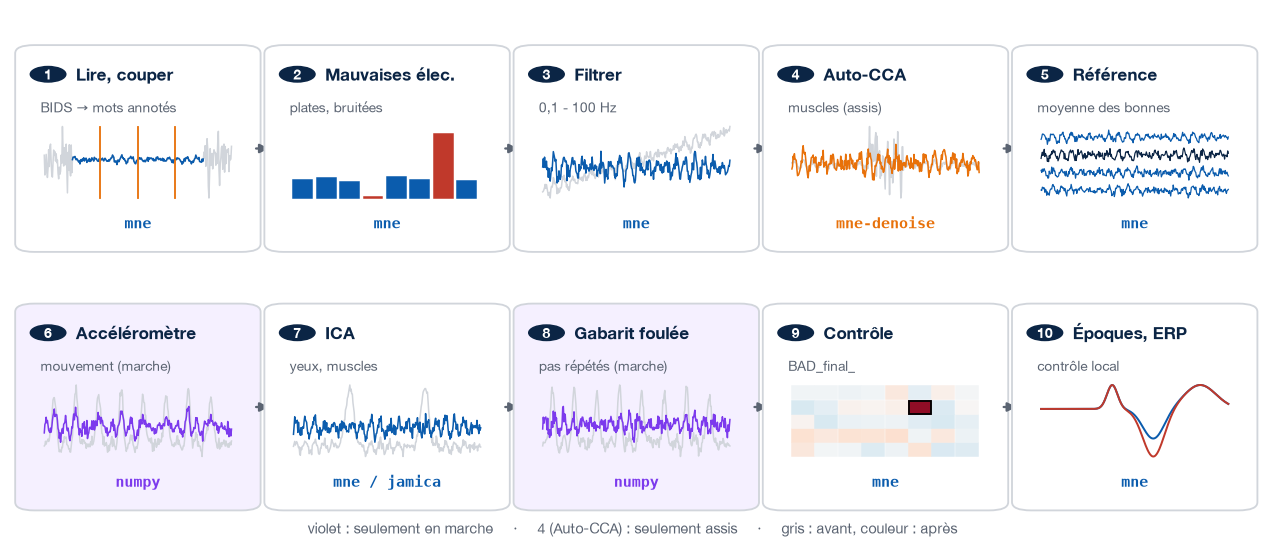

Les numéros du schéma sont ceux des étapes de la chaîne ; les parties du notebook sont dans le tableau ci-dessous.

| Partie | Contenu |
|---|---|
| 0 | Installation, données, réglages |
| 1 | Les données et la tâche |
| 2 | Couper aux déclencheurs, étiqueter les mots, joindre les blocs |
| 3 | Les mauvaises électrodes et les périodes suspectes |
| 4 | Filtrer |
| 5 | Auto-CCA : l'activité des muscles (assis) |
| 6 | La référence moyenne |
| 7 | Préparer les données de l'ICA |
| 8 | L'ICA : trouver les composantes des yeux et des muscles |
| 9 | Appliquer l'ICA, et contrôler après |
| 10 | Époques et ERP, avant et après le nettoyage |
| 11 | En marche : ce qui change |
| 12 | Tous les participants : `pretraiter()`, l'export, la vérification |
| 13 | Récapitulatif : ce qui va dans votre section Méthodes |

<div style="color:#1F2937; background:#F9FAFB; border:1px solid #E5E7EB; border-radius:6px; padding:8px 14px;"><b>Trois types de blocs</b><div style="margin:3px 0;"><span style="background:#0B5CAD; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 1</span> &nbsp;le code est complet : exécutez la cellule et lisez les commentaires.</div><div style="margin:3px 0;"><span style="background:#E8710A; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 2</span> &nbsp;complétez une ou deux lignes marquées <code>&lt;---</code>.</div><div style="margin:3px 0;"><span style="background:#7C3AED; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 3</span> &nbsp;écrivez la cellule vous-même, à partir des indices et des liens vers la documentation.</div><div style="font-size:0.9em; color:#5B6472; margin-top:4px;">Chaque exercice est suivi d'une solution repliée : essayez d'abord.</div></div>

<div style="color:#1F2937; background:#F3F4F6; border:1px solid #E5E7EB; border-radius:6px; padding:8px 14px; margin-top:6px;"><span style="background:#5B6472; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Pour aller plus loin</span> &nbsp;les détails de la chaîne, <b>facultatifs</b> : exécutez ces cellules (la suite en a besoin), lisez-les si vous voulez comprendre le code. Dans Colab, leur code est replié ; dans VS Code, repliez la section avec la flèche à gauche de son titre.</div>

<details><summary>Sur votre ordinateur ou dans Colab ?</summary>

- **Sur votre ordinateur (recommandé).** Ouvrez le notebook dans VS Code avec le noyau `env_meeg`. Les données (2,2 Go) sont
  téléchargées **une seule fois** dans `tasks/brainwalk/`, à côté des notebooks ; les notebooks 2, 3 et 4 les retrouvent.
- **Colab.** `Fichier → Enregistrer une copie dans Drive`, puis exécutez la première cellule : elle installe les paquets et télécharge
  les données sur la machine de Colab. Colab efface cette machine à la fin de chaque session : **les 2,2 Go sont téléchargés de
  nouveau à chaque session** (quelques minutes), et dans chacun des notebooks.
- Le notebook complet prend environ 10 minutes, dont 2 à 3 pour l'ICA de la marche (AMICA).
</details>

## 0. Installation, données, réglages

La cellule 0.1 prépare l'ordinateur (paquets, données) ; la cellule 0.2 choisit le participant et importe les réglages.

In [ ]:
# ---- 0.1 Les paquets (installés s'il en manque), les imports et les données
import importlib.util
import sys
from pathlib import Path

DANS_COLAB = "google.colab" in sys.modules
DEPOT = "https://raw.githubusercontent.com/thecocolab/PSY2007D-UdeM/main/"
if DANS_COLAB:                            # Colab n'a pas les fichiers du cours : on les télécharge
    !wget -q -N {DEPOT}requirements.txt {DEPOT}outils_brainwalk.py
PAQUETS = ["mne", "mne_denoise", "mne_icalabel", "onnxruntime", "picard", "jamica", "jax"]   # les paquets de ce notebook
if any(importlib.util.find_spec(p) is None for p in PAQUETS):   # il en manque : installer ceux du cours (une fois)
    %pip install -q -r requirements.txt

import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
import outils_brainwalk as ob             # fonctions du projet (fichier outils_brainwalk.py, à côté du notebook)

mne.set_log_level("ERROR")                # MNE n'affiche que les erreurs
mne.viz.set_browser_backend("matplotlib")
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False, "animation.embed_limit": 40})

DOSSIER = ob.telecharger_donnees()        # 2,2 Go la première fois (quelques minutes) ; ensuite, rien à télécharger
print("MNE", mne.__version__)

### <span style="background:#0B5CAD; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 1</span> Les réglages de la chaîne

Les valeurs à rapporter dans votre section **Méthodes**. Chacune est expliquée dans sa partie ; elles sont définies dans
`outils_brainwalk.py`, et la cellule 0.2 les importe.

| Partie | Étape | Réglage |
|---|---|---|
| 3 | Électrode plate | sous 0,1 × l'amplitude typique, ou écart-type sous 1 µV (signal enregistré) |
| 3 | Électrode bruitée | au-dessus de 3 × l'amplitude typique (assis) ; dans plus de 50 % de ses fenêtres de 5 s (en marche) |
| 3 | Période suspecte (`QC_`) | une fenêtre de 5 s au-dessus de 3 × l'amplitude typique |
| 4 | Filtre des données analysées | passe-bande 0,1-100 Hz |
| 5 | Auto-CCA (assis) | fenêtres de 10 s (chevauchement 50 %) ; retirée si la pente 7-75 Hz est au-dessus de 0 |
| 7 | Copie de l'ICA | 1-100 Hz (assis), à partir de 2 Hz (en marche) ; périodes `QC_` au-dessus de 5 × mises de côté (assis) |
| 8 | ICA | Picard (assis), AMICA (en marche) ; graine 97 ; décision : seuils 0,5, prudence « cerveau » 0,3 |
| 10 | Époques | −0,2 à 0,8 s ; ligne de base −0,2 à 0 s ; 1-40 Hz ; bonnes réponses ; bip à 5 ms près |
| 10 | Contrôle local | trop grande : 3 écarts-types robustes ; dérive : 46,2 µV ; époque abandonnée si plus de 50 % laissées ; SME : 2 × la médiane |
| 10 | Composantes | P2 140-220 ms (F3, Fz, F4, C3, Cz, C4) ; N400 300-500 ms et LPC 450-800 ms (C3, Cz, C4, P3, Pz, P4) |

In [ ]:
# ---- 0.2 Le participant et la posture ; les réglages viennent de outils_brainwalk.py
PARTICIPANT = "P010"              # un des 17 participants (ob.PARTICIPANTS)
POSTURE = "assis"                 # "assis" ; la partie 11 refait la chaîne en "marche"

from outils_brainwalk import (RAPPORT_PLAT, RAPPORT_BRUIT, PART_BRUIT, MAX_MAUVAISES, RAPPORT_QC, BANDE_ANALYSE,
                              CCA_FENETRE_S, CCA_BANDE_PENTE, CCA_PENTE, BANDE_ICA, RAPPORT_HORS_ICA, GRAINE_ICA, P_ICLABEL,
                              CORR_OEIL_ASSIS, SCORE_MUSCLE, PRUDENCE_CERVEAU, TMIN, LIGNE_DE_BASE, BANDE_ERP, BIP_MAX_MS,
                              ECART_QC, DERIVE_UV, FACTEUR_SME, COMPOSANTES, CONDITIONS, TMAX)   # les réglages du tableau

## 1. Les données et la tâche

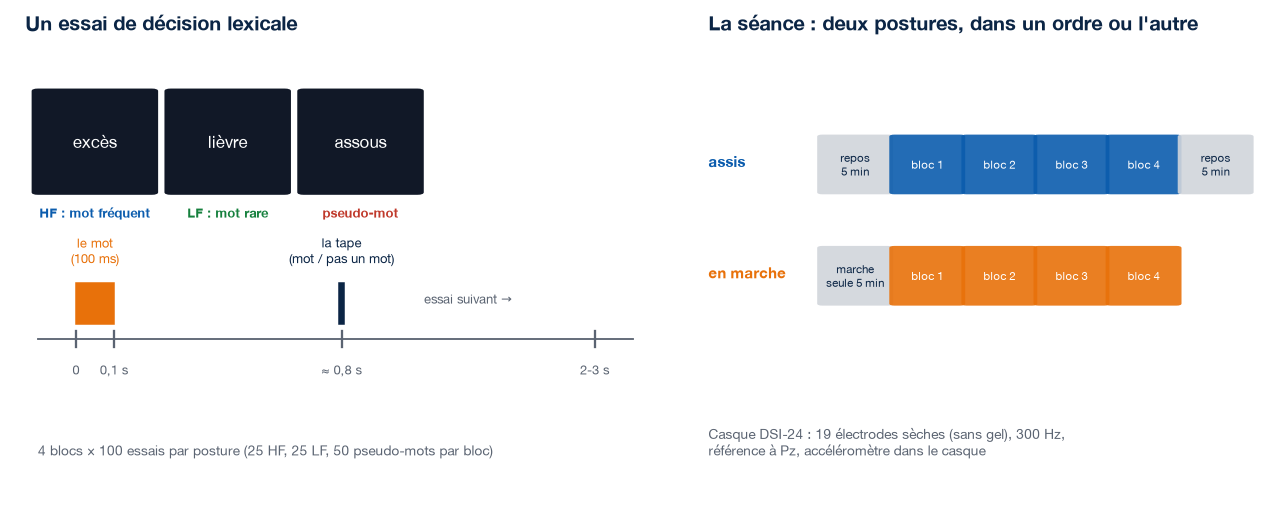

<div style="border-left:5px solid #5B6472; background:#F3F4F6; color:#1F2937; padding:10px 16px; border-radius:6px; margin:8px 0;"><b style="color:#5B6472;">Données</b><br>17 participants au format <b>BIDS</b> (une façon standard de nommer et ranger les
fichiers EEG ; Pernet et al., 2019 ; <code>bids/</code>), le comportement (<code>comportement/</code>) et
les données déjà prétraitées (<code>pretraite_00/</code>). Tout est décrit dans <code>tasks/brainwalk/LISEZMOI.md</code>.</div>

<div style="border-left:5px solid #4A3AA7; background:#F1EFFB; color:#1F2937; padding:10px 16px; border-radius:6px; margin:8px 0;"><b style="color:#4A3AA7;">Ce que dit la littérature</b><br>Les effets que les notebooks 2 et 3 chercheront. Une <b>composante</b> est une onde de l'ERP,
nommée par son signe (P : positive, N : négative) et son moment :<ul style='margin:4px 0 0 0;'><li>la <b>N400</b>, une onde négative vers 300-500 ms au centre et à l'arrière de la tête, plus grande pour les pseudo-mots que pour les mots, et pour les mots rares que pour les mots fréquents (Kutas et Federmeier, 2011) ;</li><li>la <b>P2</b>, une onde positive vers 150-250 ms à l'avant et au centre, sensible aux premières étapes de la reconnaissance du mot ;</li><li>la <b>LPC</b> (<i>late positive component</i>), une positivité tardive liée à la décision ;</li><li>en marche, une partie de l'attention va à la marche : les effets peuvent être plus petits (étude Brain Walk ; Patelaki et al., 2023).</li></ul></div>

In [ ]:
ob.carte_chaine(1)      # la chaîne : l'étape en cours en orange, les étapes déjà faites en vert

### <span style="background:#0B5CAD; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 1</span> Les fichiers BIDS d'un participant

`sub-P010_ses-001_task-LexicalDecision_acq-seatedBlock01_run-01_eeg.vhdr` : participant P010, tâche LexicalDecision, bloc 1 assis.
Chaque enregistrement a le signal (`.vhdr`, `.vmrk`, `.eeg`), `_eeg.json` (l'appareil), `_channels.tsv` (les électrodes) et
`_events.tsv` (chaque mot, chaque réponse).

In [ ]:
# ---- 1.1 Les enregistrements de ce participant dans cette posture
for nom in ob.ETIQUETTES[POSTURE]:
    fichier = ob.fichier_bids(PARTICIPANT, POSTURE, nom, "eeg.vhdr")
    print(f"{nom:13s}", fichier.name if fichier else "absent")

In [ ]:
# ---- 1.2 Ce que disent les fichiers BIDS : l'appareil et les électrodes
description = json.loads(ob.fichier_bids(PARTICIPANT, POSTURE, "bloc1", "eeg.json").read_text(encoding="utf-8"))
print("Appareil  :", description["ManufacturersModelName"], "-", description["CapManufacturersModelName"])
print("Fréquence :", description["SamplingFrequency"], "Hz")
print("Référence :", description["EEGReference"])
electrodes = pd.read_csv(ob.fichier_bids(PARTICIPANT, POSTURE, "bloc1", "channels.tsv"), sep="\t")
electrodes[["name", "type", "status"]].T

**Lire.** 19 électrodes EEG, enregistrées par rapport à **Pz** (donc Pz = 0 partout). `A1`, `A2`, `CM` et `Trigger` ne sont pas de
l'EEG. `P7` est déjà marquée `bad` : cette électrode ne marche pas (son signal est plat, figure 1.7).

In [ ]:
# ---- 1.3 Lire les enregistrements
raws, evenements = {}, {}
for nom in ob.ETIQUETTES[POSTURE]:
    vhdr = ob.fichier_bids(PARTICIPANT, POSTURE, nom, "eeg.vhdr")
    if vhdr is None:                                         # un enregistrement manque chez ce participant
        continue
    raw = mne.io.read_raw_brainvision(vhdr, preload=True)   # le signal, en volts
    raw.set_channel_types({"CM": "misc", "A1": "misc", "A2": "misc", "Trigger": "stim"})   # seules les 19 électrodes sont de l'EEG
    raw.set_montage("standard_1020")                         # la position de chaque électrode (système 10-20)
    raws[nom] = raw
    evenements[nom] = pd.read_csv(ob.fichier_bids(PARTICIPANT, POSTURE, nom, "events.tsv"), sep="\t", na_values="n/a")
    print(f"{nom:13s} {raw.times[-1] / 60:4.1f} min, {(evenements[nom]['trial_type'] == 'stimulus').sum():3d} mots")

In [ ]:
# ---- 1.4 Où sont les électrodes (vu de dessus, le nez en haut)
fig, ax = plt.subplots(figsize=(4.2, 4.2))
raws["bloc1"].plot_sensors(show_names=True, axes=ax, show=False)
ax.set_title("19 électrodes sèches, système 10-20\n(Pz est la référence)", fontsize=10)
plt.show()

In [ ]:
# ---- 1.5 Les événements : une ligne par mot et une par réponse (la tape)
colonnes = ["onset", "trial_type", "stimulus", "lexicality", "frequency_class", "accuracy", "response_time"]
evenements["bloc1"][colonnes].head(6)

### <span style="background:#E8710A; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 2</span> À vous de compléter : le comportement

Un **essai** = un mot (ou pseudo-mot) et sa réponse. La **condition** d'un essai est son type : `mot/HF` (mot fréquent), `mot/LF`
(mot rare) ou `pseudo` (pseudo-mot).

Réunissez les mots des quatre blocs, puis calculez pour chaque condition le nombre d'essais, la proportion de bonnes réponses
(`accuracy`) et le temps de réaction (TR) médian (`response_time`, en s). La fonction `ob.condition_de` donne la condition d'une ligne.

In [ ]:
# ---- Exercice
# mots = pd.concat([evenements[b][evenements[b]["trial_type"] == "stimulus"] for b in evenements if b.startswith("bloc")])
# mots["condition"] = mots.apply(ob.condition_de, axis=1)
# mots.groupby("condition").agg(essais=("stimulus", "size"), exactitude=(..., "mean"), tr_median_s=(..., "median"))   # <--- à compléter

In [ ]:
#@title Solution (à consulter après avoir essayé)
mots = pd.concat([evenements[b][evenements[b]["trial_type"] == "stimulus"] for b in evenements if b.startswith("bloc")])
mots["condition"] = mots.apply(ob.condition_de, axis=1)
mots.groupby("condition").agg(essais=("stimulus", "size"), exactitude=("accuracy", "mean"),
                              tr_median_s=("response_time", "median")).round(3)
# Les mots fréquents sont reconnus plus vite que les mots rares, et les deux plus vite que les pseudo-mots.

In [ ]:
# ---- 1.6 Un essai après l'autre : les mots, les réponses et le canal des déclencheurs (15 s du bloc 1)
ob.figure_essais(raws["bloc1"], evenements["bloc1"])

**Lire.** En haut, le canal des déclencheurs : la tablette y envoie un bip (un **déclencheur**) à chaque mot, ce qui synchronise
l'EEG et la tablette. ▼ : **la tape**, le toucher du participant sur la tablette (sa réponse : mot ou pas un mot). À Cz, pas de
réponse visible à chaque mot : un ERP fait quelques µV, l'EEG ±10 µV. Il faudra moyenner (partie 10).

In [ ]:
# ---- 1.7 Le signal brut : à quoi ressemblent un clignement et un mouvement des yeux (15 s du repos de la fin)
ob.figure_signal_brut(raws["repos_fin"], 105, 120,
                      marques=[(106.45, 106.9, "clignement", "tab:orange"), (117.25, 117.9, "saccade", "tab:purple"),
                               (117.95, 118.4, "clignement", "tab:orange")],
                      titre="Le repos de la fin, 15 s : signal brut (référence Pz)", zoom=(116.7, 118.0, ["F7", "F8"]))

**Lire.** En rouge, les électrodes près des yeux. **Clignement** : une grande onde (100-350 µV) en même temps sur Fp1, Fp2, F7, F8.
**Saccade** (un mouvement rapide des yeux, ici horizontal ; agrandie en bas) : F7 monte et F8 descend. **P7** est plate (électrode
hors d'usage), **Pz** aussi (la référence). Tout cela est bien plus grand qu'un
ERP. Pour parcourir un enregistrement : `raws["repos_fin"].plot()` après `%matplotlib qt`.

## 2. Couper aux déclencheurs, étiqueter les mots, joindre les blocs

Avant de nettoyer, on ne garde que les moments utiles et on nomme chaque mot.

- **Couper** chaque enregistrement entre son déclencheur de début et celui de fin (`raw.crop`) : avant et après, ce n'est pas la
  tâche (et souvent de grands artefacts : des signaux qui ne viennent pas du cerveau).
- **Étiqueter** chaque mot par une **annotation** (une étiquette posée sur un moment de l'enregistrement) : `mot/HF`, `mot/LF` ou
  `pseudo` (`epochs["mot"]` prendra les deux premières ensemble) ; un trou dans les données (le casque est sans fil) devient
  `BAD_perte`. MNE saute toute annotation dont le nom commence par `BAD`.
- **Joindre** les 4 blocs (`mne.concatenate_raws`) ; chaque jonction devient `BAD boundary`.

In [ ]:
# ---- 2.1 Couper, étiqueter, joindre (le code : ob.assembler, dans outils_brainwalk.py)
coupes, enregistrements, essais, parties = ob.assembler(raws, evenements)
for nom, raw in enregistrements.items():
    print(f"{nom:10s} {raw.times[-1] / 60:5.1f} min, annotations : {pd.Series(raw.annotations.description).value_counts().to_dict()}")

## 3. Les mauvaises électrodes et les périodes suspectes

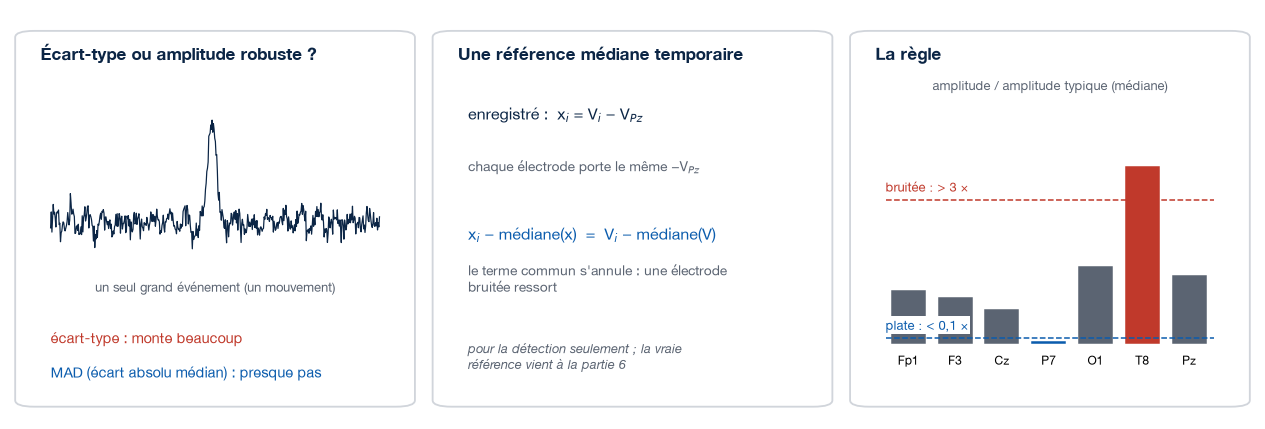

Une électrode **plate** ou **bruitée** se répandrait dans toutes les autres avec la référence moyenne (partie 6), et gênerait l'ICA
(partie 8). On la met dans `raw.info["bads"]` jusqu'à la fin, **sans jamais l'interpoler** (l'estimer à partir de ses voisines : avec
19 électrodes, elles sont trop loin). Mesures sur une copie filtrée de 1 à 40 Hz. L'**amplitude robuste** (le MAD, écart absolu
médian ; Leys et al., 2013) bouge peu pour un seul grand événement ; l'**amplitude typique** est la médiane des électrodes.

In [ ]:
ob.carte_chaine(2)

**La règle assis.** Plate : sous `RAPPORT_PLAT` × l'amplitude typique, ou écart-type sous 1 µV, sur le signal enregistré. Bruitée :
au-dessus de `RAPPORT_BRUIT` × l'amplitude typique, après la référence médiane temporaire (schéma ; Pz comprise). Mauvaise dans un
enregistrement = mauvaise dans tous.

In [ ]:
# ---- 3.1a Étape 1 : les électrodes plates, sur le signal tel qu'enregistré
plates, rapport_enregistre, et = ob.electrodes_plates(coupes)        # sous RAPPORT_PLAT × l'amplitude typique, ou écart-type < 1 µV
print("Plates :", plates or "aucune")

**Étape 2 : les électrodes bruitées.** On soustrait la référence médiane temporaire (schéma ci-dessus), puis on compare l'amplitude robuste
de chaque électrode à l'amplitude typique de son enregistrement.

In [ ]:
# ---- 3.1b Étape 2 : les électrodes bruitées, après la référence médiane temporaire
eeg = coupes["bloc1"].copy().pick("eeg").ch_names                     # les 19 électrodes, Pz comprise
utilisables = [c for c in eeg if c != "Pz" and c not in plates]       # celles de la référence médiane (ni Pz, ni les plates)
amplitude = {nom: ob.amplitudes(raw, utilisables) for nom, raw in coupes.items()}   # l'amplitude robuste de chaque électrode

rapport = pd.DataFrame({nom: a["robuste"] for nom, a in amplitude.items()})   # une colonne par enregistrement
typique = rapport.median()                                            # l'amplitude typique de chaque enregistrement
rapport = rapport / typique                                           # chaque électrode / l'amplitude typique

bruitees = list(rapport.index[(rapport > RAPPORT_BRUIT).any(axis=1) & ~rapport.index.isin(plates)])
print("Bruitées :", bruitees or "aucune")
rapport.round(2)

**Étape 3 : Pz, puis la liste finale.** Pz vaut 0 dans le fichier ; par rapport à la référence médiane, son signal est celui du capteur de
référence lui-même : on le juge avec la même règle. Les mauvaises électrodes vont dans `raw.info["bads"]`.

In [ ]:
# ---- 3.1c Étape 3 : Pz, puis les mauvaises électrodes de la posture
reference = {nom: np.median(raw.copy().pick(utilisables).filter(1, 40).get_data() * 1e6, axis=0) for nom, raw in coupes.items()}
rapport_pz = pd.Series({nom: ob.mad(m) for nom, m in reference.items()}) / typique   # l'amplitude de Pz / l'amplitude typique
if (rapport_pz > RAPPORT_BRUIT).any():
    bruitees.append("Pz")

MAUVAISES = sorted(plates + bruitees)
for raw in enregistrements.values():
    raw.info["bads"] = list(MAUVAISES)            # MNE laisse maintenant ces électrodes de côté, jusqu'à la fin
utilisables = [c for c in utilisables if c not in MAUVAISES]

print("Mauvaises électrodes :", MAUVAISES)
print(f"Pz : de {rapport_pz.min():.1f} à {rapport_pz.max():.1f} × l'amplitude typique (bruitée au-dessus de {RAPPORT_BRUIT:g})")
if len(MAUVAISES) > MAX_MAUVAISES:
    print(f"ATTENTION : plus de {MAX_MAUVAISES} mauvaises électrodes. Regardez les enregistrements avant de continuer.")

### <span style="background:#E8710A; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 2</span> À vous de compléter : un seuil plus strict

Avec `RAPPORT_BRUIT = 2`, quelles électrodes seraient bruitées ? Utilisez le tableau `rapport` (sans modifier `MAUVAISES`). Pourquoi un
seuil trop bas pose-t-il problème avec 19 électrodes seulement ?

In [ ]:
# ---- Exercice
# seuil = ...                                                               # <--- à compléter
# print(list(rapport.index[(rapport > seuil).any(axis=1)]))

In [ ]:
#@title Solution (à consulter après avoir essayé)
seuil = 2
print(list(rapport.index[(rapport > seuil).any(axis=1)]))
# Chez P010 : aucune, de justesse (O1 atteint 1,97 × au bloc 1, F7 1,90 ×). Avec 19 électrodes, chaque électrode écartée compte : la
# référence moyenne et l'ICA reposent sur moins d'électrodes, et les régions des ERP perdent des mesures. Un seuil trop bas écarterait
# des électrodes simplement un peu plus grandes que les autres (O1 et O2, à l'arrière, où l'alpha est fort ; F7 et F8, près des yeux).

### Les périodes suspectes : des annotations `QC_`, pas `BAD`

Certains problèmes ne durent que quelques secondes. Même mesure par **fenêtres de 5 s** (le **contrôle de qualité**, QC) : au-dessus
de `RAPPORT_QC` × l'amplitude typique, une annotation `QC_grande_amplitude` (sur l'électrode, ou sur tout le scalp) ; sous
`RAPPORT_PLAT` ×, `QC_contact` (l'électrode a perdu le contact). Trois sortes d'annotations suivent les données jusqu'à la fin :

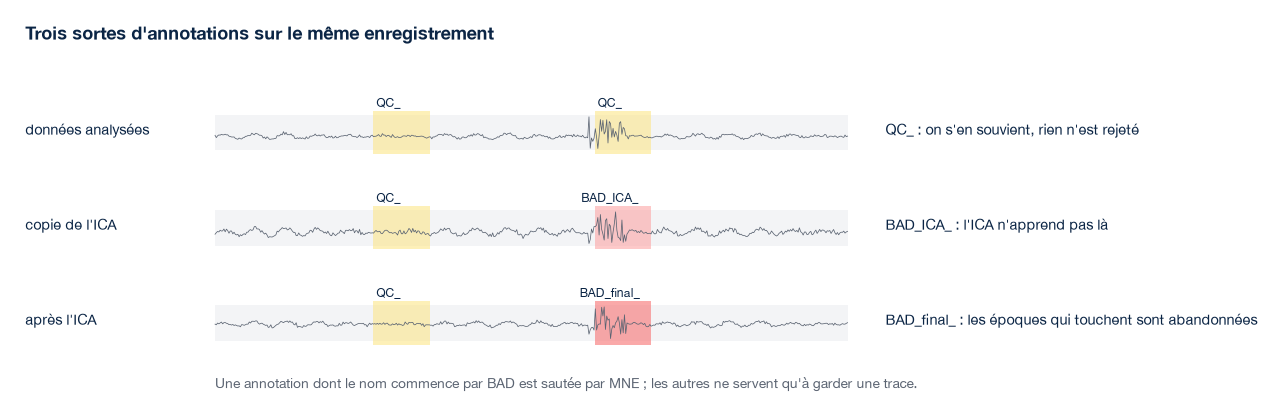

In [ ]:
# ---- 3.2 Le contrôle de 5 s : chaque électrode / l'amplitude typique de sa fenêtre
qualite, fenetres = ob.qualite_fenetres(enregistrements, coupes, parties, utilisables, utilisables)
fig, ax = plt.subplots(figsize=(13, 4.6))
image = ob.carte_qualite(qualite, fenetres, parties, MAUVAISES, ax,
                         "Amplitude robuste / amplitude typique, une valeur toutes les 5 s (ligne du haut : la fenêtre / la fenêtre typique)")
ob.barre_couleurs(fig, image, ax)
plt.show()

**Lire.** Une colonne = 5 s, une ligne = une électrode (P7, plate, n'est plus montrée) ; rouge = plus grande que l'amplitude typique
de sa fenêtre, bleu = plus petite. Une électrode qui perd le contact ferait une longue bande, rouge (bruit) ou bleu foncé (presque
plate).

In [ ]:
# ---- 3.3 Les périodes suspectes deviennent des annotations QC_ (avec leur électrode)
tableau_qc = ob.periodes_qc(qualite, fenetres, MAUVAISES)
ob.ajouter_annotations(enregistrements, tableau_qc)        # suivent les données jusqu'à la fin, ne rejettent rien
print(len(tableau_qc), "périodes suspectes ; debut : en s depuis le début de l'enregistrement (la tâche : les 4 blocs joints)")
tableau_qc.round(2)

**Lire.** Chez P010 assis : aucune longue bande, seulement 4 fenêtres isolées au-dessus de 3 × (T8 au repos du début, F8 au bloc 3
et au repos de la fin, Fz au bloc 3).

## 4. Filtrer

Un signal EEG est une **somme de fréquences** ; son **spectre** montre la taille de chacune. `raw.filter(l_freq, h_freq)` : un
**passe-haut** (`l_freq` seul) retire les **dérives** lentes (le signal qui monte ou descend lentement), un **passe-bas** (`h_freq`
seul) l'activité rapide, un **passe-bande** les deux. Le bruit du réseau électrique (60 Hz) est presque absent : le casque l'annule.

In [ ]:
ob.carte_chaine(3)
ob.demo_filtres()

### La coupure du passe-haut dépend de l'ERP

La N400 et la LPC sont des ondes **lentes**. Un passe-haut trop haut les rapetisse et crée de **fausses ondes** de signe opposé
(Tanner et al., 2015 ; Zhang et al., 2024 recommandent 0,2 Hz au plus). Appuyez sur lecture, et lisez les amplitudes dans le titre.

In [ ]:
# ---- 4.1 Animation : ce qu'un passe-haut fait à la N400 et à la LPC
ob.animation_passe_haut()

**Lire.** À 0,1 Hz, l'ERP est presque intact. À 1 Hz, la N400 paraît **plus** négative et la LPC plus petite qu'en réalité.

**Le filtre de la chaîne : 0,1 à 100 Hz.** 0,1 Hz garde la N400 et la LPC ; 100 Hz garde l'activité des muscles, que l'Auto-CCA
(partie 5) et ICLabel (partie 8) doivent voir pour la reconnaître.

In [ ]:
# ---- 4.2 Filtrer les enregistrements de 0,1 à 100 Hz
filtre_pz = {nom: raw.copy().filter(*BANDE_ANALYSE, picks="eeg") for nom, raw in enregistrements.items()}   # « _pz » : encore référencé à Pz
print(f"Passe-bande {BANDE_ANALYSE[0]:g}-{BANDE_ANALYSE[1]:g} Hz :", ", ".join(filtre_pz))

## 5. Auto-CCA : l'activité des muscles répandue sur le scalp (assis)

L'activité des muscles touche plusieurs électrodes à la fois, aux mêmes fréquences que l'EEG : un filtre retirerait aussi le cerveau.
La **BSS-CCA** (De Clercq et al., 2006) recombine les électrodes en **composantes**, de la plus lisse (le cerveau change en douceur)
à la moins lisse (les muscles ressemblent à un bruit). L'**Auto-CCA** retire automatiquement celles dont le spectre ne baisse pas avec
la fréquence (Janani et al., 2018). Ici (et pour l'ICA, partie 8), une « composante » est un signal séparé par la méthode, pas une
onde de l'ERP comme la N400.

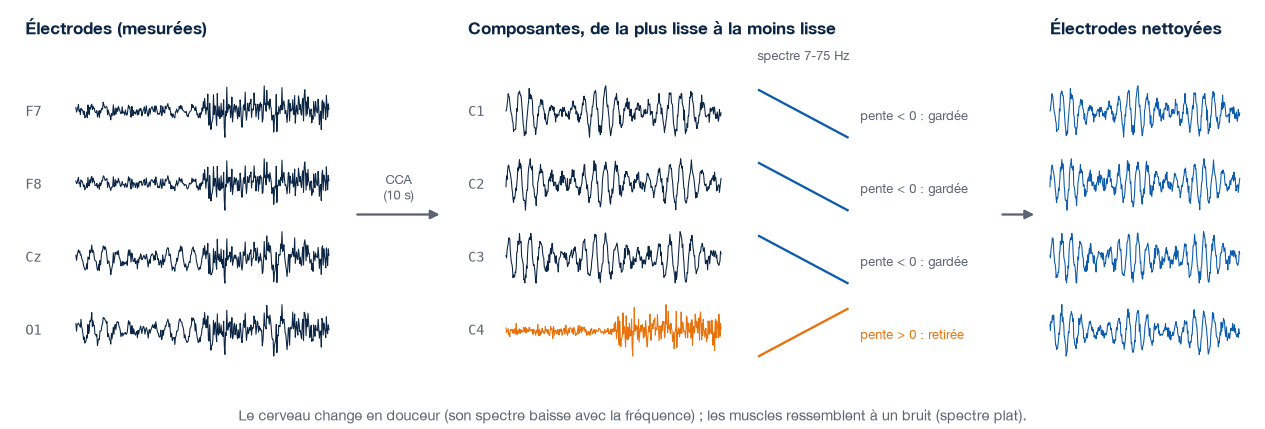

<div style="border-left:5px solid #0F766E; background:#E7F5F2; color:#1F2937; padding:10px 16px; border-radius:6px; margin:8px 0;"><b style="color:#0F766E;">Nouveau paquet : mne-denoise (BSSCCA)</b><br><code>BSSCCA(...).fit_transform(raw)</code> rend une copie nettoyée,
fenêtre par fenêtre ; les électrodes de <code>info["bads"]</code> restent hors du calcul.
<a href="https://mne.tools/mne-denoise/stable/">Documentation</a></div>

<div style="border-left:5px solid #E8710A; background:#FDF1E7; color:#1F2937; padding:10px 16px; border-radius:6px; margin:8px 0;"><b style="color:#E8710A;">Le seuil est un compromis</b><br>Seuil 0 : le seuil prudent de Fitzgibbon et al. (2016). Le seuil −0,48 de
Janani et al. (115 électrodes) retire ici une grande partie de l'alpha (le rythme de 8-13 Hz, fort à l'arrière de la tête ;
exercice). Validé assis seulement : pas d'Auto-CCA en marche. Un
groupe qui étudie l'alpha doit discuter de ce que l'Auto-CCA en retire.</div>

In [ ]:
ob.carte_chaine(4)

In [ ]:
# ---- 5.1 Auto-CCA : 10 s à la fois, retirer les composantes dont le spectre ne baisse pas avec la fréquence
from mne_denoise.bss_cca import BSSCCA

analyse_pz, cca = {}, {}
for nom, raw in filtre_pz.items():
    copie = raw.copy()
    copie.info["bads"] = sorted(set(MAUVAISES) | {"Pz"})     # Pz (encore toute à zéro) et les mauvaises restent hors du calcul
    cca[nom] = BSSCCA(lag_samples=1, slope_threshold=CCA_PENTE, slope_band=CCA_BANDE_PENTE,
                      segment_len=CCA_FENETRE_S, overlap=0.5)
    analyse_pz[nom] = cca[nom].fit_transform(copie)
    analyse_pz[nom].info["bads"] = list(MAUVAISES)

arriere = [c for c in ["O1", "O2"] if c not in MAUVAISES]          # l'arrière de la tête (l'alpha)
sfreq = filtre_pz["tache"].info["sfreq"]
ob.resume_cca(filtre_pz, analyse_pz, cca, MAUVAISES)            # ce que l'Auto-CCA a retiré, enregistrement par enregistrement

In [ ]:
# ---- 5.2 Chaque composante de chaque fenêtre : la pente de son spectre (rouge : retirée)
ob.figure_cca(cca, filtre_pz)

**Lire.** À gauche : « la plus autocorrélée » = la plus lisse ; les moins lisses (à droite) ont les pentes les plus hautes, et
celles au-dessus de 0 (rouge) sont retirées. À droite : la plupart des fenêtres perdent 0 à 2 composantes ; quelques fenêtres de la
tâche (vers 13-14 min) jusqu'à 10, et le repos de la fin environ 5. Le prix (cellule 5.1) : 2 à 10 % de l'alpha à O1 et O2.

### <span style="background:#E8710A; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 2</span> À vous de compléter : le seuil de Janani et al.

Refaites l'Auto-CCA du repos de la fin avec `slope_threshold=-0.48`. Quelle part de l'alpha (8-13 Hz) à O1 et O2 est retirée, comparée
au seuil 0 ?

In [ ]:
# ---- Exercice
# copie = filtre_pz["repos_fin"].copy()
# copie.info["bads"] = sorted(set(MAUVAISES) | {"Pz"})
# strict = BSSCCA(lag_samples=1, slope_threshold=..., slope_band=CCA_BANDE_PENTE, segment_len=CCA_FENETRE_S, overlap=0.5)   # <--- à compléter
# propre_strict = strict.fit_transform(copie)
# print(ob.part_retiree(filtre_pz["repos_fin"], propre_strict, arriere, 8, 13))

In [ ]:
#@title Solution (à consulter après avoir essayé)
copie = filtre_pz["repos_fin"].copy()
copie.info["bads"] = sorted(set(MAUVAISES) | {"Pz"})
strict = BSSCCA(lag_samples=1, slope_threshold=-0.48, slope_band=CCA_BANDE_PENTE, segment_len=CCA_FENETRE_S, overlap=0.5)
propre_strict = strict.fit_transform(copie)
print(f"alpha retiré à O1/O2 : seuil -0,48 {100 * ob.part_retiree(filtre_pz['repos_fin'], propre_strict, arriere, 8, 13):.0f} %, "
      f"seuil 0 {100 * ob.part_retiree(filtre_pz['repos_fin'], analyse_pz['repos_fin'], arriere, 8, 13):.0f} %")
# Le seuil de Janani et al. retire bien plus d'alpha : avec 17 électrodes, les composantes mélangent plus de sources qu'avec 115.

## 6. La référence moyenne

Jusqu'ici, chaque électrode est mesurée par rapport à Pz. La **référence moyenne** lui soustrait, à chaque instant, la moyenne des
bonnes électrodes : aucune électrode n'est favorisée, et Pz retrouve un signal.

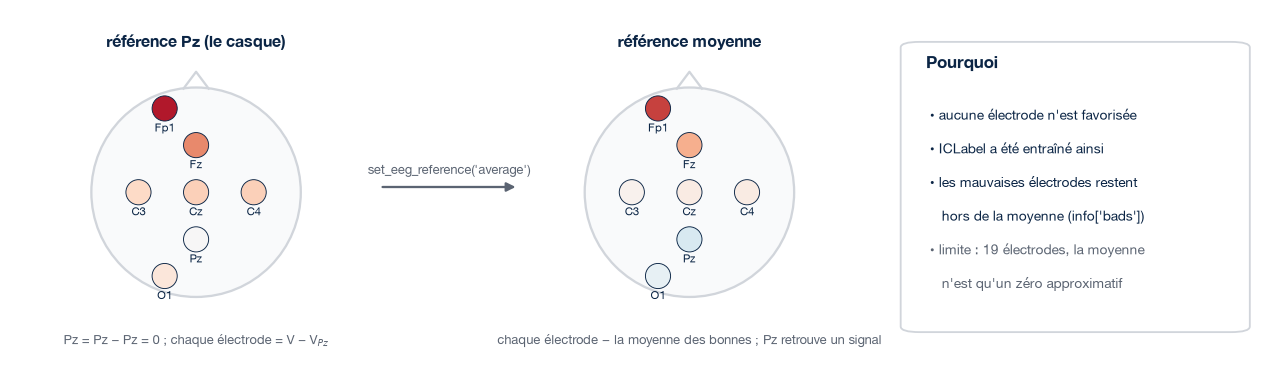

In [ ]:
# ---- 6.1 La référence moyenne des bonnes électrodes
ob.carte_chaine(5)
analyse = {nom: raw.copy().set_eeg_reference("average") for nom, raw in analyse_pz.items()}
BONNES = [c for c in analyse["tache"].copy().pick("eeg").ch_names if c not in MAUVAISES]   # les bonnes électrodes, Pz comprise
somme = analyse["tache"].get_data(picks=BONNES).sum(axis=0)
print(f"Pz varie maintenant (écart-type {analyse['tache'].get_data(picks='Pz').std() * 1e6:.1f} µV) ; "
      f"somme des {len(BONNES)} bonnes électrodes : {np.abs(somme).max() * 1e6:.0e} µV (zéro à chaque instant)")

In [ ]:
# ---- 6.2 Les clignements, et un clignement vu avec les deux références
clignements = ob.trouver_clignements(analyse["tache"], BONNES)     # un événement au pic de chaque clignement
print(f"{len(clignements)} clignements dans la tâche ({len(clignements) / (analyse['tache'].times[-1] / 60):.1f} par minute)")
t_clignement = ob.figure_clignement_references(analyse_pz["tache"], analyse["tache"], clignements, BONNES)

**Lire.** Avec la référence moyenne, le clignement reste à l'avant, mais une petite copie inversée apparaît à l'arrière. L'ICA (partie 8)
le retire partout à la fois. (`ob.trouver_clignements` : un pic sur Fp1 **et** Fp2 ; ces clignements servent aussi à la colonne
`sans_clignement` des fichiers exportés.)

## 7. Préparer les données de l'ICA

L'ICA (partie 8) apprend ses composantes sur une **copie** des données, préparée pour elle :

- **Une copie à 1-100 Hz** sert à ajuster l'ICA : les dérives lentes la gênent (Winkler et al., 2015), mais 1 Hz déformerait les ERP. La
  solution sera appliquée aux données 0,1-100 Hz (partie 9) : l'ICA ne combine que les électrodes, ses poids valent à toutes les fréquences.
- **`BAD_ICA_`** sur la copie seulement, pour les périodes QC graves (perte de contact, tout le scalp, > 5 ×) : l'ICA ne doit pas
  apprendre d'artefacts rares et énormes. Les clignements restent : elle doit les voir.

In [ ]:
# ---- 7.1 La copie de l'ICA (1-100 Hz) et ses annotations BAD_ICA_
ob.carte_chaine(6)
copie_ica = {nom: raw.copy().filter(*BANDE_ICA["assis"], picks="eeg") for nom, raw in analyse.items()}
retiree = ((tableau_qc["description"] == "QC_contact") | (tableau_qc["electrodes"] == "toutes")
           | (tableau_qc["rapport"] >= RAPPORT_HORS_ICA))
tableau_qc["retiree_de_l_ica"] = retiree
ob.ajouter_annotations(copie_ica, tableau_qc[retiree], prefixe="BAD_ICA_", par_electrode=False)   # sans électrode : l'ICA les prend toutes
entrainement = mne.concatenate_raws([raw.copy() for raw in copie_ica.values()])   # repos du début + tâche + repos de la fin
n_gardes = entrainement.get_data(picks=BONNES[0], reject_by_annotation="omit").shape[1]
print(f"{retiree.sum()} période(s) QC mises de côté ; {n_gardes:,} échantillons pour l'ICA ({n_gardes / sfreq / 60:.1f} min) ; "
      f"la règle habituelle en demande au moins {30 * len(BONNES) ** 2:,} (30 × {len(BONNES)}²)")

## 8. L'ICA : trouver les composantes des yeux et des muscles

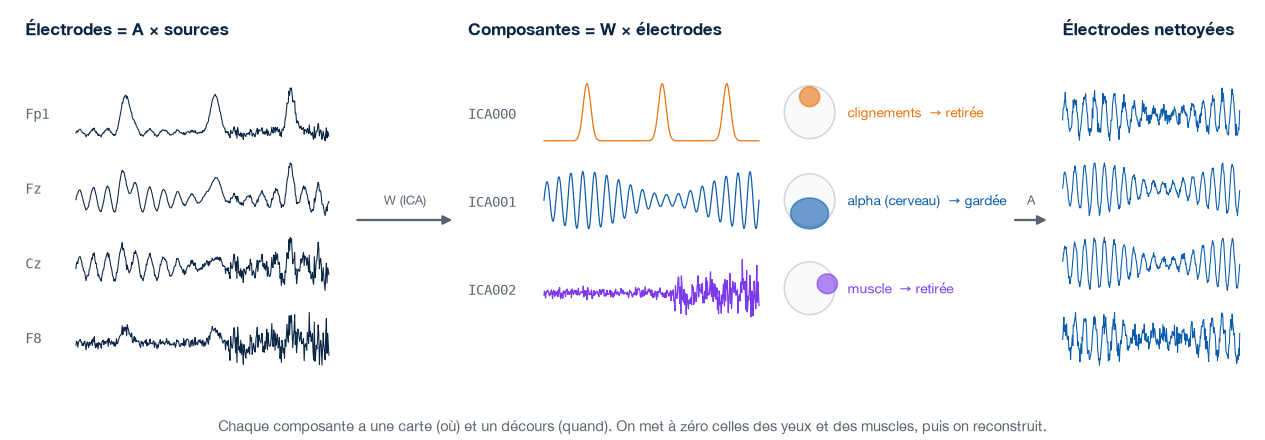

Chaque électrode enregistre un **mélange** de sources ; l'ICA les **démélange** en supposant qu'elles sont indépendantes (Makeig et al.,
1996). Autant de composantes que le **rang** des données (le nombre de signaux vraiment différents) : 18 bonnes électrodes − 1 (la
référence moyenne) = 17. D'abord, sur un exemple fabriqué :

In [ ]:
# ---- 8.1 Comment l'ICA démélange : deux sources, deux électrodes
ob.carte_chaine(7)
ob.animation_ica()

**Lire.** L'ICA tourne les données jusqu'à ce que les sorties soient le moins « gaussiennes » possible (le moins en forme de cloche ;
un signal fait de pics rares, comme les clignements, l'est très peu). Au pic de la courbe de non-gaussianité (à droite), une sortie ne
contient que les clignements et l'autre que l'alpha : l'ICA a retrouvé les sources sans les connaître. La vraie ICA fait la même
chose en 17 dimensions ; ici avec l'algorithme **Picard**, réglé comme Infomax étendu (l'ICA avec laquelle ICLabel a été entraîné).

In [ ]:
# ---- 8.2 Ajuster l'ICA (Picard) sur la copie, sans ses périodes BAD_ICA_
n_composantes = mne.compute_rank(entrainement, tol=1e-6, tol_kind="relative")["eeg"]   # le rang des bonnes électrodes
ica = mne.preprocessing.ICA(n_components=n_composantes, method="picard",
                            fit_params=dict(ortho=False, extended=True),   # Picard réglé comme Infomax étendu (l'ICA d'ICLabel)
                            random_state=GRAINE_ICA, max_iter=2000)
ica.fit(entrainement, reject_by_annotation=True)                           # saute les BAD_ICA_ et les pertes de données
print(ica)

In [ ]:
# ---- 8.3 Les topographies des composantes
fig = ica.plot_components(show=False)
fig.set_size_inches(11, 6)
plt.show()

**Lire.** **Clignement** : carte forte et symétrique à l'avant. **Mouvement horizontal des yeux** : F7 contre F8. **Muscle** : un point
au bord du casque. **Cerveau** : une carte lisse.

<div style="border-left:5px solid #0F766E; background:#E7F5F2; color:#1F2937; padding:10px 16px; border-radius:6px; margin:8px 0;"><b style="color:#0F766E;">Nouveau paquet : mne-icalabel</b><br>ICLabel (Pion-Tonachini et al., 2019) donne à chaque composante la
probabilité de 7 genres de sources (cerveau, œil, muscle...). Entraîné sur de l'EEG avec gel et beaucoup d'électrodes : avec
19 électrodes sèches, c'est un
<b>avis</b>, pas la vérité. On ajoute donc d'autres preuves. <a href="https://mne.tools/mne-icalabel/">Documentation</a></div>

In [ ]:
# ---- 8.4 ICLabel : quel genre de source est chaque composante ?
etiquettes = ob.etiquettes_iclabel(entrainement, ica)          # composantes × 7 classes
ob.figure_iclabel(etiquettes)

In [ ]:
# ---- 8.5 D'autres preuves : les substituts de l'œil et le score de muscle de MNE
# Le DSI-24 n'a pas d'électrode à côté des yeux (EOG, électro-oculogramme) : Fp1 et Fp2 sont au-dessus des yeux (clignements) et HEOG = F7 − F8 compare la
# gauche et la droite (mouvements horizontaux). Corrélation de chaque composante avec chacun, de 1 à 10 Hz
correlations = ob.correlations_yeux(ica, entrainement, MAUVAISES, etiquettes.index)
score_muscle = pd.Series(ica.find_bads_muscle(entrainement)[1], index=etiquettes.index)   # pente 7-45 Hz × bord du casque × un seul point
pd.concat([correlations.add_prefix("r_"), score_muscle.rename("score_muscle")], axis=1).round(2).T

### La décision assis : deux preuves du même genre doivent s'accorder

| Genre | Preuve | Elle vote quand |
|---|---|---|
| œil | ICLabel | la probabilité « œil » est d'au moins 0,5 (`P_ICLABEL`) |
| œil | substitut de l'œil | \|r\| avec Fp1, Fp2 ou HEOG d'au moins 0,5 (`CORR_OEIL_ASSIS`) |
| œil | topographie | le plus grand poids est à Fp1, Fp2, F7 ou F8, et Fp1 et Fp2 ont le même signe (clignement), ou la gauche et la droite du front des signes opposés (mouvement horizontal) |
| muscle | ICLabel | la probabilité « muscle » est d'au moins 0,5 |
| muscle | score de muscle MNE | le score est d'au moins 0,5 (`SCORE_MUSCLE`) |

(*r* : la corrélation entre le signal de la composante et celui du substitut.) **Retirée** : au moins deux votes du même genre.
**À revoir** (gardée) : un seul vote, ou ICLabel « cerveau » ≥ 0,3. Sinon **gardée**.

In [ ]:
# ---- 8.6 La décision : la règle du tableau (le code : ob.decision_assis, dans outils_brainwalk.py)
preuves = ob.decision_assis(ica, etiquettes, correlations, entrainement)   # une ligne par composante : ses preuves, sa décision
ica.exclude = [k for k in range(ica.n_components_) if preuves["decision"].iloc[k] == "retirer"]
print("Retirées :", [preuves.index[k] for k in ica.exclude], "| à revoir (gardées) :",
      list(preuves.index[preuves["decision"] == "revoir"]))
preuves.round(2)

In [ ]:
# ---- 8.7 Regarder de plus près les composantes retirées et à revoir
choisies = [k for k in range(ica.n_components_) if preuves["decision"].iloc[k] in ("retirer", "revoir")]
ob.figure_composantes(ica, preuves, entrainement, choisies, "Les composantes retirées et à revoir")

**Lire.** Pour chaque composante : sa carte, 4 s de son décours (son signal dans le temps ; noir : 1-10 Hz, la bande des yeux) et
son spectre. Un muscle a un
spectre qui monte entre 10 et 30 Hz, là où celui du cerveau baisse.

### <span style="background:#7C3AED; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 3</span> À vous de construire : examiner une composante à revoir

Objectif : afficher les propriétés détaillées d'une composante « à revoir » (ou, s'il n'y en a pas, de la première composante gardée),
puis décider si vous la retireriez.

<div style="border-left:5px solid #7C3AED; background:#F5F0FF; color:#1F2937; padding:10px 16px; border-radius:6px; margin:8px 0;"><b style="color:#7C3AED;">Indices</b><br><ul style='margin:4px 0 0 0;'><li>Les composantes à revoir : <code>preuves.index[preuves['decision'] == 'revoir']</code> ; leur numéro est la position dans <code>preuves</code>.</li><li><code>ica.plot_properties(entrainement, picks=[k])</code> montre la carte, le spectre, l'image des époques et la variance.</li><li>Documentation : <a href='https://mne.tools/stable/generated/mne.preprocessing.ICA.html#mne.preprocessing.ICA.plot_properties'>ICA.plot_properties</a>.</li></ul></div>

In [ ]:
# ---- Votre cellule

In [ ]:
#@title Solution (à consulter après avoir essayé)
a_revoir = [k for k in range(ica.n_components_) if preuves["decision"].iloc[k] == "revoir"]
k = a_revoir[0] if a_revoir else next(k for k in range(ica.n_components_) if preuves["decision"].iloc[k] == "garder")
print(preuves.index[k], preuves.iloc[k][["classe", "decision", "raison"]].to_dict())
ica.plot_properties(entrainement, picks=[k], show=False)
plt.show()
# Chez P010, ICA001 : une carte concentrée vers F8, un décours lent qui suit HEOG (r = -0,90) et aucun pic alpha : plutôt un
# mouvement horizontal des yeux, qu'on pourrait retirer. Une composante du cerveau aurait une carte lisse et un pic alpha (10 Hz)
# dans son spectre, comme ICA003 (figure 8.7).

## 9. Appliquer l'ICA, et contrôler après

`ica.apply(raw)` met à zéro les composantes de `ica.exclude`, puis recalcule les électrodes à partir des composantes gardées, sur
**chaque échantillon** des données 0,1-100 Hz.

In [ ]:
# ---- 9.1 Appliquer l'ICA aux enregistrements analysés
ob.carte_chaine(8)
nettoye = {nom: ica.apply(raw.copy()) for nom, raw in analyse.items()}
ob.figure_clignement_ica(analyse["tache"], nettoye["tache"], clignements, BONNES)
ob.figure_traces({"avant l'ICA": (analyse["tache"], "tab:red"), "après l'ICA": (nettoye["tache"], "k")}, t_clignement,
                 titre="Les mêmes 8 s de la tâche avant (rouge) et après (noir) l'ICA")

**Lire.** Le clignement disparaît de l'avant ; le reste du signal ne change presque pas.

**Contrôler après l'ICA.** Le même contrôle de 5 s : une période QC de **tout le scalp** encore au-delà du seuil devient `BAD_final_`
(les époques qui la touchent, partie 10, seront abandonnées). Une période d'une seule électrode reste `QC_` : le contrôle local
(partie 10) laissera cette électrode de côté dans ces époques.

In [ ]:
# ---- 9.2 Le même contrôle de 5 s après l'ICA, et BAD_final_ pour ce qui reste inutilisable
qualite_apres, _ = ob.qualite_fenetres(nettoye, coupes, parties, list(qualite.index[1:]), utilisables)
final = {nom: raw.copy() for nom, raw in nettoye.items()}
tableau_qc = ob.bad_final(tableau_qc, qualite_apres, fenetres, final)
fig, axes = plt.subplots(2, 1, figsize=(13, 8.6), layout="constrained")
for ax, (nom, t) in zip(axes, [("Avant l'ICA", qualite), ("Après l'ICA", qualite_apres)]):
    image = ob.carte_qualite(t, fenetres, parties, MAUVAISES, ax, f"{nom} (cadres : les périodes QC de la partie 3)",
                             periodes=tableau_qc)
ob.barre_couleurs(fig, image, axes)
plt.show()
tableau_qc.round(2)

**Lire.** Après l'ICA, Fp1 et Fp2 deviennent bleues : sans les clignements, elles sont plus petites que les autres. Chez P010, les 4
périodes QC sont encore au-delà du seuil (colonne `apres_ica`), mais chacune sur une seule électrode : aucune ne devient
`BAD_final_` (colonne `final`).

## 10. Époques et ERP, avant et après le nettoyage

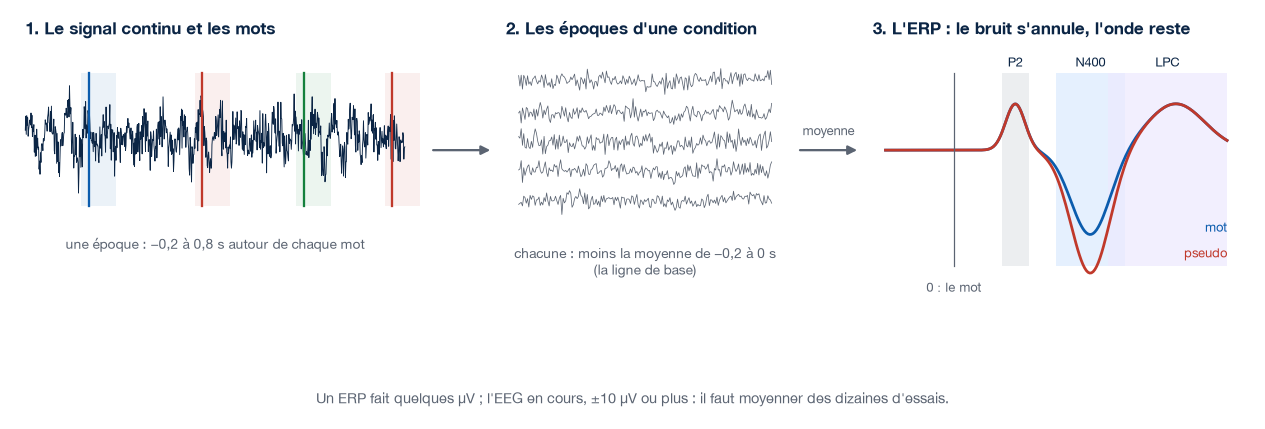

- On compare **avant** (filtre et référence seulement) et **après** le nettoyage, sur les mêmes époques.
- **1-40 Hz** : le passe-haut à 1 Hz retire les dérives des électrodes sèches, au prix d'une LPC déformée (animation de la partie 4) ;
  vérifiez la LPC avec `BANDE_ERP = (0.1, 40.0)` (exercice ci-dessous).
- Abandonnées : les époques qui touchent un `BAD` ; gardées : les bonnes réponses dont le bip confirme le mot (à 5 ms près).

In [ ]:
# ---- 10.1 Une époque par mot, avant et après le nettoyage
ob.carte_chaine(9)
avant = enregistrements["tache"].copy().filter(*BANDE_ERP, picks="eeg").set_eeg_reference("average")   # pas nettoyé
apres = final["tache"].copy().filter(*BANDE_ERP, picks="eeg")                                          # nettoyé
evenements_mots, _ = mne.events_from_annotations(apres, event_id=ob.EVENT_ID)
metadonnees = essais[["trial", "block", "trial_in_block", "stimulus", "condition", "accuracy", "response_time",
                      "marker_residual_ms"]].reset_index(drop=True)
epochs = {version: mne.Epochs(donnees, evenements_mots, ob.EVENT_ID, tmin=TMIN, tmax=TMAX, baseline=LIGNE_DE_BASE,
                              metadata=metadonnees, preload=True)
          for version, donnees in [("avant nettoyage", avant), ("après nettoyage", apres)]}
communes = np.intersect1d(epochs["avant nettoyage"].selection, epochs["après nettoyage"].selection)   # les mêmes époques
epochs = {version: ep[np.isin(ep.selection, communes)] for version, ep in epochs.items()}
md_ = epochs["après nettoyage"].metadata
garder = ((md_["marker_residual_ms"].abs() <= BIP_MAX_MS) & (md_["accuracy"] == 1)).to_numpy()    # bonne réponse, bip confirmé
epochs = {version: ep[garder] for version, ep in epochs.items()}
print({nom: len(epochs["après nettoyage"][nom]) for nom in CONDITIONS}, "époques sur", len(essais), "mots")

### Le contrôle local : laisser une électrode de côté dans une époque, pas toute l'époque

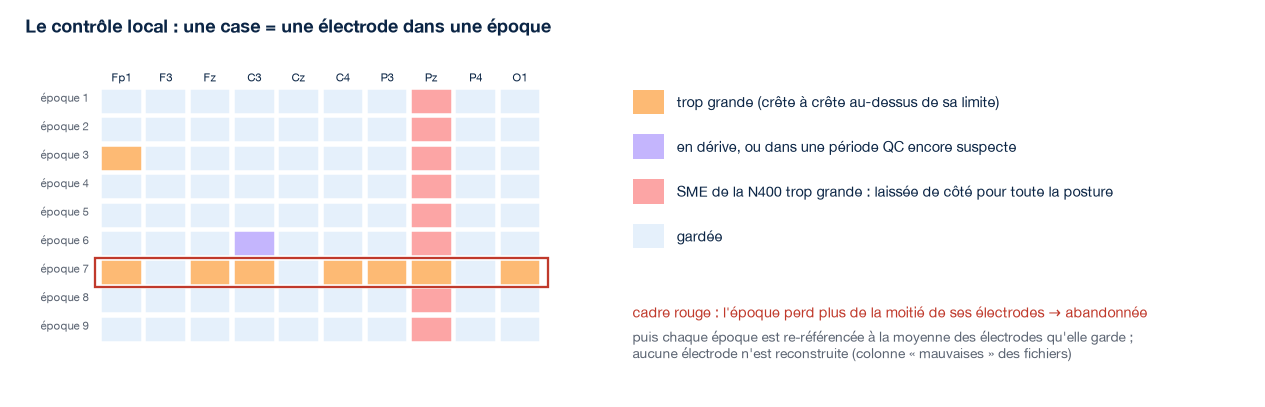

Une électrode laissée de côté dans une époque y est **non mesurée** (colonne `mauvaises` des fichiers exportés, partie 12). Les règles :

- une électrode est laissée de côté dans une époque si elle y est **trop grande** (son crête à crête, le maximum moins le minimum,
  dépasse sa médiane de `ECART_QC` écarts-types robustes), si elle **dérive** de plus de `DERIVE_UV` µV, ou si l'époque tombe dans une
  de ses périodes `QC_` encore au-delà du seuil (partie 9) ;
- une époque qui perd plus de la moitié de ses électrodes est abandonnée ;
- une électrode dont la **SME** de la N400 (l'erreur de mesure standardisée : l'imprécision de son amplitude moyenne, en µV ; Luck
  et al., 2021) dépasse `FACTEUR_SME` × la médiane est laissée de côté pour toute la posture, avec sa partenaire (C3/C4, P3/P4).

Le code : `controle_local` dans `outils_brainwalk.py`.

In [ ]:
# ---- 10.2 Le contrôle local
controle = ob.controle_local(epochs["après nettoyage"], MAUVAISES, tableau_qc, final["tache"].first_time)
ob.appliquer_controle_local(epochs, controle, MAUVAISES)     # référence par époque, colonne « laissees », info["bads"]
ob.figure_controle_local(controle)
laissee = controle["laissee"][:, controle["jugees"]]
print(f"Laissées de côté : {int(laissee.sum())} électrode-époques sur {laissee.size} ({100 * laissee.mean():.1f} %) ; "
      f"époques abandonnées : {int(controle['perdue'].sum())} ; laissées de côté pour la posture : {controle['trop_bruitees'] or 'aucune'}")

**Lire.** Chez P010 assis, chaque électrode est laissée de côté dans moins de 3 % des époques. Pz dérive plus souvent que les autres,
et sa SME de la N400 dépasse 2 × la médiane (tirets) : elle est laissée de côté pour toute la posture assis.

In [ ]:
# ---- 10.3 La P2, la N400 et la LPC, avant et après le nettoyage
MAUVAISES_POSTURE = MAUVAISES + controle["trop_bruitees"]
ob.figure_erp(epochs, MAUVAISES_POSTURE, f"{PARTICIPANT}, {POSTURE}")
amplitude_erp, sme_erp = ob.mesures_erp(epochs, MAUVAISES_POSTURE)
amplitude_erp.round(2)

**Lire.** Les petites cartes montrent la région de chaque composante (sans Pz). La P2 change peu ; la **LPC** change le plus (mots
fréquents : de 2,27 à 0,86 µV) : autour de la réponse, une partie de l'activité venait sans doute des yeux et des muscles. Chez **un**
participant, quelques dixièmes de µV entre conditions sont dans le bruit : les effets se testent sur le groupe (notebook 2).

### <span style="background:#E8710A; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 2</span> À vous de compléter : l'effet N400 de ce participant

À partir de `amplitude_erp`, calculez l'effet de lexicalité (mot vs pseudo-mot) dans la fenêtre N400 après nettoyage :
pseudo − mot/HF (en µV). La N400 est
une onde négative : quel signe attendez-vous ?

In [ ]:
# ---- Exercice
# n400 = amplitude_erp[("N400", "après nettoyage")]
# effet = ...                                             # <--- à compléter
# print(f"pseudo - HF : {effet:+.2f} µV")

In [ ]:
#@title Solution (à consulter après avoir essayé)
n400 = amplitude_erp[("N400", "après nettoyage")]
effet = n400["pseudo"] - n400["mot/HF"]
print(f"pseudo - HF : {effet:+.2f} µV")
# On attend un effet négatif (N400 plus grande pour les pseudo-mots). Chez P010 : -0,11 µV, le bon signe mais très petit. Chez un
# seul participant, il peut être petit ou de l'autre signe : c'est sur les 17 participants qu'on le teste (notebook 2).

### <span style="background:#7C3AED; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 3</span> À vous de construire : la LPC sans le passe-haut à 1 Hz

Objectif : refaire les époques **après nettoyage** avec `BANDE_ERP = (0.1, 40.0)` et comparer l'amplitude de la LPC (et de la N400) avec
celle de 1-40 Hz. Ce choix est à justifier dans votre section Méthodes.

<div style="border-left:5px solid #7C3AED; background:#F5F0FF; color:#1F2937; padding:10px 16px; border-radius:6px; margin:8px 0;"><b style="color:#7C3AED;">Indices</b><br><ul style='margin:4px 0 0 0;'><li>Partez de <code>final['tache']</code>, filtrez de 0,1 à 40 Hz, et créez les époques comme en 10.1 avec <code>evenements_mots</code> et <code>metadonnees</code>.</li><li>Gardez les mêmes essais : <code>ep[np.isin(ep.selection, epochs['après nettoyage'].selection)]</code>.</li><li>Moyennez la région de la LPC (<code>COMPOSANTES['LPC']</code>, sans <code>MAUVAISES_POSTURE</code>) dans sa fenêtre, pour chaque condition : <code>ep[cond].average().copy().pick(region).crop(*fenetre).data.mean() * 1e6</code>.</li></ul></div>

In [ ]:
# ---- Votre cellule

In [ ]:
#@title Solution (à consulter après avoir essayé)
lent = final["tache"].copy().filter(0.1, 40.0, picks="eeg")
ep = mne.Epochs(lent, evenements_mots, ob.EVENT_ID, tmin=TMIN, tmax=TMAX, baseline=LIGNE_DE_BASE, metadata=metadonnees, preload=True)
ep = ep[np.isin(ep.selection, epochs["après nettoyage"].selection)]
for comp in ["N400", "LPC"]:
    region = [c for c in COMPOSANTES[comp]["region"] if c not in MAUVAISES_POSTURE]
    lents = {n: float(ep[n].average().copy().pick(region).crop(*COMPOSANTES[comp]["fenetre"]).data.mean() * 1e6) for n in CONDITIONS}
    print(comp, "0,1-40 Hz :", {n: round(v, 2) for n, v in lents.items()}, "| 1-40 Hz :",
          amplitude_erp[(comp, "après nettoyage")].round(2).to_dict())
# Sans le passe-haut à 1 Hz, la LPC est plus grande et la N400 moins négative (animation de la partie 4). Les époques à 0,1 Hz sont aussi
# plus bruitées (dérives lentes des électrodes sèches) : c'est le compromis.

## 11. En marche : ce qui change

Même participant, **en marche** : la tête est secouée à chaque pas et les électrodes bougent. Cinq étapes changent (Gorjan et al., 2022) :

| Partie | Assis | En marche | Pourquoi |
|---|---|---|---|
| 3. Mauvaises électrodes | une valeur par enregistrement | jugées dans les fenêtres de 5 s : bruitées dans plus de la moitié d'entre elles (`PART_BRUIT`), en deux passages | une électrode peut n'être grande que pendant quelques pas (Klug et al., 2024 ; Gonsisko et al., 2023) |
| 5. Muscles | Auto-CCA | pas d'Auto-CCA | validée sur des participants assis seulement |
| 6 bis. Mouvement de la tête | — | régression sur l'accéléromètre du casque | la tête bouge les électrodes à chaque pas |
| 7-8. ICA | Picard, copie à 1 Hz, deux preuves | **AMICA**, copie à 2 Hz, la règle Brain Walk (œil, muscle, électrode seule) | l'ICA des études mobiles (Klug et al., 2024) |
| 9 bis. Foulées | — | soustraire ce qui se répète à chaque foulée (Gwin et al., 2010) | ce que l'ICA ne peut pas regrouper |

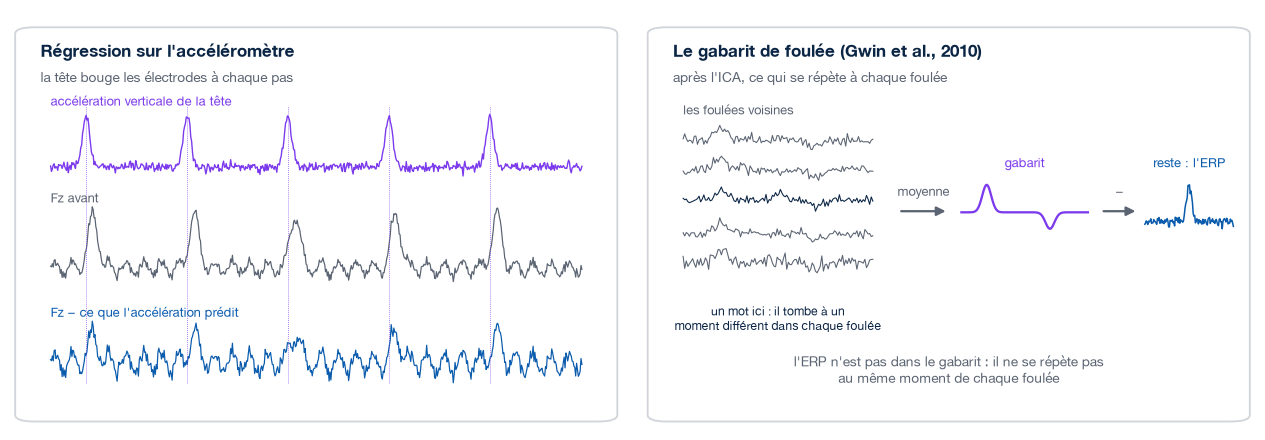

<div style="border-left:5px solid #E8710A; background:#FDF1E7; color:#1F2937; padding:10px 16px; border-radius:6px; margin:8px 0;"><b style="color:#E8710A;">Une limite à écrire dans votre rapport</b><br>Les deux postures ne sont pas nettoyées par exactement la même
chaîne : une différence assis / marche peut venir de la posture <b>ou</b> du prétraitement.</div>

L'essentiel : les cellules 11.1 et 11.2 (les données en marche), puis 11.9 (les ERP en marche, avant et après le nettoyage).
Les étapes qui changent sont détaillées entre les deux, dans « Pour aller plus loin ».

In [ ]:
# ---- 11.1 Lire, couper, étiqueter, joindre (comme aux parties 1 et 2)
raws_m, evenements_m = ob.lire_enregistrements(PARTICIPANT, "marche")              # = la cellule 1.3
coupes_m, enregistrements_m, essais_m, parties_m = ob.assembler(raws_m, evenements_m)   # = la cellule 2.1
for nom, raw in enregistrements_m.items():
    print(f"{nom:13s} {raw.times[-1] / 60:5.1f} min")

In [ ]:
# ---- 11.2 Le signal brut en marche : les pas et un clignement (15 s de marche seule, sans tâche)
ob.figure_signal_brut(raws_m["marche_seule"], 350, 365,
                      marques=[(352.0, 355.0, "pas (agrandis)", "tab:purple"), (362.3, 362.9, "clignement", "tab:orange")],
                      titre="La marche seule (sans tâche), 15 s : signal brut (référence Pz)", zoom=(352.0, 355.0, ["Fz", "Cz"]))

**Lire.** Une onde pointue à chaque pas (environ 2 par seconde), surtout à Fz, aussi grande qu'un clignement.

### <span style="background:#5B6472; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Pour aller plus loin</span> Les étapes en marche, une par une

Les étapes identiques appellent une fonction de `outils_brainwalk.py` qui contient le même code que la partie indiquée ; celles qui
changent sont écrites ici.

| Cellule | Ce qu'elle fait | Comme à |
|---|---|---|
| 11.1 | `ob.lire_enregistrements`, `ob.assembler` : lire, couper, étiqueter, joindre | 1.3 et 2.1 |
| 11.3 | les mauvaises électrodes (**change**), puis les périodes `QC_` | partie 3 |
| 11.4 | filtrer, référence moyenne, clignements (pas d'Auto-CCA) ; puis la régression sur l'accéléromètre (**nouveau**) | 4.2, 6.1, 6.2 |
| 11.6 | la copie de l'ICA, AMICA, ICLabel, `ob.decision_marche` (**change**) | 7.1, 8.2 à 8.6 |
| 11.8 | appliquer l'ICA ; puis le gabarit de foulée (**nouveau**) | 9.1 |
| 11.9 | `ob.bad_final`, `ob.epoques_mots`, `ob.controle_local`, `ob.mesures_erp` : contrôle après l'ICA, époques, contrôle local, ERP | 9.2, 10.1 à 10.3 |

**Mauvaises électrodes en marche** (partie 3, règle changée) : bruitée si au-dessus de `RAPPORT_BRUIT` × l'amplitude typique dans plus
de `PART_BRUIT` de ses fenêtres de 5 s (la chaîne BeMoBIL utilise 0,2 à 0,5 ; Klug et al., 2022), en deux passages : le second refait
la mesure sans les bruitées du premier dans la référence médiane (Gonsisko et al., 2023).

In [ ]:
#@title 11.3 Les mauvaises électrodes en marche (ob.mauvaises_electrodes)
me = ob.mauvaises_electrodes("marche", coupes_m, enregistrements_m, parties_m)   # la règle en marche : les fenêtres de 5 s
MAUVAISES_M, qualite_m, fenetres_m, utilisables_m = me["mauvaises"], me["qualite"], me["fenetres"], me["utilisables"]
for raw in enregistrements_m.values():
    raw.info["bads"] = list(MAUVAISES_M)
tableau_qc_m = ob.periodes_qc(qualite_m, fenetres_m, MAUVAISES_M)   # les périodes QC_ : comme la cellule 3.3
ob.ajouter_annotations(enregistrements_m, tableau_qc_m)
print("Mauvaises :", MAUVAISES_M, "| les autres sont trop grandes dans au plus",
      ", ".join(f"{100 * v:.0f} % ({c})" for c, v in me["part"].drop(MAUVAISES_M, errors="ignore").nlargest(4).items()),
      f"de leurs fenêtres | {len(tableau_qc_m)} périodes QC")
fig, ax = plt.subplots(figsize=(13, 5))
image = ob.carte_qualite(qualite_m, fenetres_m, parties_m, MAUVAISES_M, ax, "En marche : amplitude robuste / amplitude typique, toutes les 5 s")
ob.barre_couleurs(fig, image, ax)
plt.show()

**Lire.** Seule P7 (plate) est mauvaise. Pz est souvent rouge (41 % de ses fenêtres), mais sous la limite de 50 % : elle est gardée,
et le contrôle local (partie 10) la jugera époque par époque. C4 n'est très grande qu'au bloc 3 : des périodes `QC_`, pas une
mauvaise électrode.

### Le mouvement de la tête : une régression sur l'accéléromètre

Étape nouvelle (« 6 bis »), juste après la référence moyenne. L'**accéléromètre** du casque mesure les mouvements de la tête. Pour
chaque électrode, une **régression** prédit, à partir de l'accélération (3 axes et norme, 0,5-12 Hz, jusqu'à 200 ms avant), la part
du signal qui suit le mouvement, et on la soustrait (régression *ridge*, freinée pour ne pas trop s'ajuster ; une par minute).
Appliquée seulement si elle prédit au moins 2 % de données **mises de côté** (un bloc de 5 s sur 4, non utilisé pour l'ajuster) :
sinon, elle retirerait du hasard.

In [ ]:
#@title 11.4 Filtrer (pas d'Auto-CCA en marche), référence moyenne, clignements, puis la régression sur l'accéléromètre
analyse_m = {nom: raw.copy().filter(*BANDE_ANALYSE, picks="eeg").set_eeg_reference("average") for nom, raw in enregistrements_m.items()}   # = 4.2 et 6.1
BONNES_M = [c for c in analyse_m["tache"].copy().pick("eeg").ch_names if c not in MAUVAISES_M]
clignements_m = ob.trouver_clignements(analyse_m["tache"], BONNES_M)        # = 6.2
acceleration = {nom: ob.acceleration_tete(PARTICIPANT, "marche", nom, raws_m, coupes_m) for nom in coupes_m}
pas = {nom: ob.trouver_pas(a, sfreq) for nom, a in acceleration.items()}   # un pic de l'accélération verticale par pas
avant_mouvement = {nom: raw.copy() for nom, raw in analyse_m.items()}      # gardé pour les figures
tableau_mouvement = ob.regression_mouvement(analyse_m, acceleration, coupes_m, parties_m, BONNES_M)   # modifie analyse_m
print({nom: f"{len(p)} pas" for nom, p in pas.items()})
tableau_mouvement

In [ ]:
#@title 11.5 Ce que la régression a retiré : le pas moyen avant et après
taille_pas = ob.figure_pas({"avant la régression": ob.pas_moyen(avant_mouvement, pas, parties_m, BONNES_M),
                            "après": ob.pas_moyen(analyse_m, pas, parties_m, BONNES_M)},
                           "La taille du pas moyen à chaque bonne électrode")

**Lire.** Le **pas moyen** : l'EEG moyenné autour de chaque pas. La régression n'est appliquée que là où elle prédit les données mises
de côté : chez P010, dans 3 enregistrements sur 5 (colonne `appliquee` : marche seule, blocs 3 et 4). À Fz, le pas moyen passe
d'environ 100 à 35 µV ; une partie reste : ce qui ne suit pas la tête (le contact de chaque électrode, les muscles du cou).

### AMICA, et la règle de décision Brain Walk

Ces étapes remplacent les parties 7 et 8. **AMICA** (Palmer et al., 2011) : l'ICA des études mobiles, sur une copie à partir de
2 Hz (Klug et Gramann, 2021). Elle rejette elle-même les échantillons qu'elle n'explique pas (Klug et al., 2024).

<div style="border-left:5px solid #0F766E; background:#E7F5F2; color:#1F2937; padding:10px 16px; border-radius:6px; margin:8px 0;"><b style="color:#0F766E;">Nouveau paquet : jamica</b><br><code>jamica</code> : AMICA en Python, qui rend un objet <code>ICA</code> de MNE
(Esmaeili et al., 2026). Environ 2 minutes sur un portable.</div>

**La règle Brain Walk** :

| Genre | Retirée quand |
|---|---|
| œil | ICLabel donne « œil » au moins 0,6, ou « œil » est son premier choix **et** la composante suit Fp1, Fp2 ou HEOG avec \|r\| ≥ 0,4 |
| muscle | ICLabel donne « muscle » au moins 0,5 |
| électrode seule | au moins 60 % de la carte sur une électrode **et** au moins 10 % de la variance de la tâche (la part du signal qu'elle explique) ; ou ICLabel « bruit d'électrode » ≥ 0,5 |

En marche, beaucoup de composantes sont une électrode qui bouge seule : on ne retire que les grandes (≥ 10 % de la variance).

In [ ]:
#@title 11.6 AMICA, ICLabel et la règle Brain Walk (2 à 3 minutes)
entrainement_m, entrainement_iclabel_m, retiree_m = ob.copies_ica("marche", analyse_m, tableau_qc_m)   # copies : 2 Hz et 1-100 Hz
tableau_qc_m["retiree_de_l_ica"] = retiree_m
ica_m = ob.ajuster_ica("marche", entrainement_m)                   # AMICA (jamica), sur des morceaux de 2 s
etiquettes_m = ob.etiquettes_iclabel(entrainement_iclabel_m, ica_m)                                   # = 8.4
correlations_m = ob.correlations_yeux(ica_m, entrainement_iclabel_m, MAUVAISES_M, etiquettes_m.index)   # = 8.5
preuves_m = ob.decision_marche(ica_m, etiquettes_m, correlations_m, analyse_m["tache"], BONNES_M)   # la règle du tableau
ica_m.exclude = [k for k in range(ica_m.n_components_) if preuves_m["decision"].iloc[k] == "retirer"]
print("Retirées :", ", ".join(f"{preuves_m.index[k]} ({preuves_m['classe'].iloc[k]})" for k in ica_m.exclude))
preuves_m[["ICLabel_cerveau", "ICLabel_oeil", "ICLabel_muscle", "focalite", "electrode_max", "variance_pct", "classe", "decision",
           "raison"]].round(2)

In [ ]:
#@title 11.7 Les composantes retirées
ob.figure_composantes(ica_m, preuves_m, entrainement_iclabel_m, ica_m.exclude, "En marche : les composantes retirées")

**Lire.** Chez P010 en marche : 2 composantes des yeux (ICA004, ICA014) et 3 « électrode seule » (Pz, F8, C3), qui portent chacune 17
à 35 % de la variance de la tâche. Le décours d'ICA000 (Pz) a un pic environ 2 fois par seconde, comme les pas. Aucune composante de
muscle n'est retirée ici.

### Le gabarit de foulée

Étape nouvelle (« 9 bis »), juste après avoir appliqué l'ICA (partie 9). Il reste ce qui se répète à chaque **foulée** (deux pas) :
on soustrait de chaque foulée la moyenne des 20 foulées voisines, le **gabarit** (Gwin et al., 2010 ; schéma au début de la partie 11).
Après l'ICA plutôt qu'avant : un choix de la chaîne Brain Walk (essayé chez P010 : avant l'ICA, les ERP étaient moins précis ; ce
test n'est pas refait ici).

In [ ]:
#@title 11.8 Appliquer l'ICA, puis soustraire le gabarit de foulée
nettoye_m = {nom: ica_m.apply(raw.copy()) for nom, raw in analyse_m.items()}  # = 9.1
apres_ica_m = {nom: raw.copy() for nom, raw in nettoye_m.items()}             # gardé pour la figure
n_foulees = ob.retirer_foulees(nettoye_m, pas, parties_m, BONNES_M)           # modifie nettoye_m
print(n_foulees, "foulées")
ob.figure_pas({"avant la régression": ob.pas_moyen(avant_mouvement, pas, parties_m, BONNES_M),
               "après l'ICA": ob.pas_moyen(apres_ica_m, pas, parties_m, BONNES_M),
               "après le gabarit": ob.pas_moyen(nettoye_m, pas, parties_m, BONNES_M)},
              "La taille du pas moyen à chaque bonne électrode, étape par étape");

**Lire.** L'ICA réduit encore le pas moyen ; après le gabarit, il a presque disparu à toutes les électrodes.

### Les ERP en marche, avant et après le nettoyage

Retour à l'essentiel : la même partie 10, en marche.

In [ ]:
# ---- 11.9 Contrôle après l'ICA, époques, contrôle local et ERP (comme aux parties 9 et 10)
qualite_apres_m, _ = ob.qualite_fenetres(nettoye_m, coupes_m, parties_m, list(qualite_m.index[1:]), utilisables_m)   # = 9.2
qualite_apres_m.loc[[c for c in MAUVAISES_M if c in qualite_apres_m.index]] = np.nan
final_m = {nom: raw.copy() for nom, raw in nettoye_m.items()}
tableau_qc_m = ob.bad_final(tableau_qc_m, qualite_apres_m, fenetres_m, final_m)                  # = 9.2 (BAD_final_)
epochs_m = ob.epoques_mots(final_m["tache"], enregistrements_m["tache"], essais_m, MAUVAISES_M)   # = 10.1
controle_m = ob.controle_local(epochs_m["après nettoyage"], MAUVAISES_M, tableau_qc_m, final_m["tache"].first_time)   # = 10.2
ob.appliquer_controle_local(epochs_m, controle_m, MAUVAISES_M)
MAUVAISES_POSTURE_M = MAUVAISES_M + controle_m["trop_bruitees"]
print({nom: len(epochs_m["après nettoyage"][nom]) for nom in CONDITIONS}, "époques ; laissées de côté pour la posture :",
      controle_m["trop_bruitees"] or "aucune")
ob.figure_erp(epochs_m, MAUVAISES_POSTURE_M, f"{PARTICIPANT}, marche")                          # = 10.3
amplitude_m, sme_m = ob.mesures_erp(epochs_m, MAUVAISES_POSTURE_M)
print("SME (µV), médiane des conditions, avant → après le nettoyage : "
      + " ; ".join(f"{c} {sme_m[(c, 'avant nettoyage')].median():.2f} → {sme_m[(c, 'après nettoyage')].median():.2f}" for c in COMPOSANTES))

**Lire.** En marche, le nettoyage change bien plus les ERP qu'assis : avant, ils varient de ± 8 µV (le bruit des pas) ; après, de
quelques µV. Leur **SME** (partie 10 : l'imprécision de la mesure) est divisée par 5 à 7. Laissées de côté pour la posture : Pz assis
(10.2) ; P3, T7 et P4 en marche. La région de la N400 et de la LPC (C3, Cz, C4, P3, Pz, P4) n'a donc chez P010 que 5 électrodes
assis et 4 en marche (les petites cartes).

## 12. <span style="background:#5B6472; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Pour aller plus loin</span> Tous les participants : `pretraiter()`, l'export, la vérification

Facultatif : les fichiers que lisent les notebooks 2, 3 et 4 sont déjà téléchargés. Cette partie montre comment ils ont été faits.

Les parties 1 à 11 ont nettoyé **un** participant, cellule par cellule. Pour les 17, la même chaîne est réunie dans deux fonctions de
`outils_brainwalk.py` :

- `ob.pretraiter(participant, posture)` : toutes les étapes des parties 1 à 11 d'un coup, pour une posture ;
- `ob.exporter(...)` : écrit les fichiers d'époques que lisent les notebooks 2, 3 et 4.

La cellule 12.1 vérifie que `pretraiter()` donne **exactement** le résultat obtenu pas à pas ici (une ligne ✓ par vérification) ;
la cellule 12.2 exporte P010 et compare avec les fichiers téléchargés ; la cellule 12.3 est la boucle qui a produit `pretraite_00/`.

In [ ]:
#@title 12.1 Le notebook et outils_brainwalk.py donnent-ils le même résultat ? (3 à 4 minutes)
verifications = {}
pas_a_pas = {"assis": (MAUVAISES, tableau_qc, ica, epochs, controle), "marche": (MAUVAISES_M, tableau_qc_m, ica_m, epochs_m, controle_m)}
resultats = {}
for posture, (mauvaises, tqc, ica_, ep, cl) in pas_a_pas.items():
    r = resultats[posture] = ob.pretraiter(PARTICIPANT, posture, verbeux=False)
    verifications[f"{posture} : mêmes mauvaises électrodes"] = r["mauvaises"] == mauvaises
    verifications[f"{posture} : mêmes périodes QC"] = r["tableau_qc"][["enregistrement", "debut", "duree", "description", "electrodes"]].equals(
        tqc[["enregistrement", "debut", "duree", "description", "electrodes"]])
    verifications[f"{posture} : mêmes composantes retirées"] = r["ica"].exclude == ica_.exclude
    verifications[f"{posture} : mêmes époques"] = np.array_equal(r["epochs"]["après nettoyage"].selection, ep["après nettoyage"].selection)
    verifications[f"{posture} : mêmes signaux"] = np.allclose(r["epochs"]["après nettoyage"].get_data(), ep["après nettoyage"].get_data(),
                                                              rtol=1e-6, atol=1e-12)
    verifications[f"{posture} : mêmes électrodes laissées de côté"] = r["controle_local"]["trop_bruitees"] == cl["trop_bruitees"]
for texte, ok in verifications.items():
    print("✓" if ok else "✗", texte)

### L'export : les fichiers de `pretraite_00/`

`ob.exporter` écrit, pour un participant, les fichiers que lisent les notebooks 2, 3 et 4 (décrits dans `LISEZMOI.md`) :

| Fichier | Contenu |
|---|---|
| `sub-PXXX_epo.fif` | une époque par essai gardé, de −0,2 à 1,0 s autour du mot, 1-40 Hz, sans ligne de base ; les deux postures |
| `tape/sub-PXXX_tape_epo.fif` | les mêmes essais, de −0,8 à 0,2 s autour de la tape (le toucher sur la tablette : la réponse) |
| `longues/...` | de −1,0 à 1,5 s autour du mot (et autour de la tape), échantillonnées à 100 Hz, pour le temps-fréquence (notebook 3) |
| `sans_tache/...` | les repos et la marche seule, en fenêtres de 2 s |

La colonne `mauvaises` de chaque époque liste les électrodes **non mesurées** dans cette époque (laissées de côté, partie 10, ou
mauvaises pour la posture) ; `info['bads']` réunit les mauvaises des deux postures. Les fichiers téléchargés ont été faits avec cette
chaîne ; seule l'Auto-CCA était alors écrite à la main (même méthode, mêmes réglages).

In [ ]:
#@title 12.2 Exporter P010 dans derivatives/, et comparer avec les fichiers téléchargés
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)   # (MNE prévient que les deux postures sont l'une après l'autre)
sortie = DOSSIER / "derivatives" / "pretraite_00"            # un dossier à part : les fichiers téléchargés ne sont pas touchés
bilan = ob.exporter([resultats["assis"], resultats["marche"]], sortie)
for fichier in [f"sub-{PARTICIPANT}_epo.fif", f"tape/sub-{PARTICIPANT}_tape_epo.fif", f"longues/sub-{PARTICIPANT}_longues_epo.fif"]:
    nouveau, telecharge = mne.read_epochs(sortie / fichier), mne.read_epochs(DOSSIER / "pretraite_00" / fichier)
    print(f"{fichier:38s} {len(nouveau)} époques (téléchargé : {len(telecharge)}) | info['bads'] : {nouveau.info['bads']}")
nouveau.metadata.head()

**Lire.** Une ligne par fichier : le nombre d'époques refaites ici, et entre parenthèses celui du fichier téléchargé (les mêmes, à une
époque près pour `longues/`). `info['bads']` : P7 (les deux postures), Pz (assis), P3, T7 et P4 (en marche). Le tableau : une ligne
par essai gardé ; `tr_ms` : le TR ; `sans_clignement` : aucun clignement de 0,25 s avant le mot à 0,25 s après la tape ; `mauvaises` :
les électrodes non mesurées.

### La boucle sur les 17 participants (facultatif)

C'est cette boucle qui a produit les fichiers de `pretraite_00/` que vous avez téléchargés : pour chaque participant, `ob.pretraiter()`
dans chaque posture enregistrée, puis `ob.exporter()`. Vous n'avez **pas** à la lancer : la suite (notebooks 2, 3 et 4) lit les
fichiers téléchargés. Elle prend environ 5 minutes par participant (près d'une heure et demie en tout) ; pour la relancer :
`RELANCER = True`. Les nouveaux fichiers vont dans `derivatives/pretraite_00/`.

In [ ]:
#@title 12.3 Tous les participants (facultatif)
RELANCER = False                       # True : relancer toute la chaîne pour les 17 participants
if RELANCER:
    comportement = pd.read_csv(DOSSIER / "comportement" / "essais.csv")    # le comportement (TR...) de tous les participants
    for participant in ob.PARTICIPANTS:
        if (sortie / f"sub-{participant}_epo.fif").exists():               # déjà exporté : on passe au suivant
            print(participant, ": déjà fait")
            continue
        debut = time.time()
        postures = [p for p in ob.POSTURES                                  # les postures dont ce participant a des blocs
                    if any(ob.fichier_bids(participant, p, n, "eeg.vhdr") for n in ob.ETIQUETTES[p] if n.startswith("bloc"))]
        ob.exporter([ob.pretraiter(participant, p) for p in postures], sortie, comportement)   # la chaîne, puis l'export
        print(f"{participant} : {time.time() - debut:.0f} s")

## 13. Récapitulatif : ce qui va dans votre section Méthodes

| Étape | Assis | En marche | Fonction |
|---|---|---|---|
| Lire, couper | coupé aux déclencheurs ; mots annotés ; pertes de données `BAD` ; 4 blocs joints | idem | `read_raw_brainvision`, `crop`, `concatenate_raws` |
| Mauvaises électrodes | plates (< 0,1 × l'amplitude typique ou écart-type < 1 µV) ; bruitées (> 3 × après une référence médiane temporaire) ; jamais interpolées | bruitées dans > 50 % des fenêtres de 5 s, deux passages | `info["bads"]` |
| Périodes suspectes | `QC_` par fenêtre de 5 s (> 3 ×) | idem | annotations |
| Filtre | 0,1-100 Hz | idem | `raw.filter` |
| Muscles | Auto-CCA : BSS-CCA, fenêtres de 10 s, pente 7-75 Hz > 0 | — | `BSSCCA` (mne-denoise) |
| Référence | moyenne des bonnes électrodes | idem, puis régression sur l'accéléromètre | `set_eeg_reference` |
| ICA | Picard (Infomax étendu) sur une copie 1-100 Hz ; deux preuves du même genre | AMICA sur une copie à partir de 2 Hz ; règle Brain Walk | `ICA`, `jamica.fit_ica`, ICLabel |
| Après l'ICA | `BAD_final_` pour tout le scalp encore au-delà du seuil | idem, après le gabarit de foulée (Gwin et al., 2010) | annotations |
| Époques | −0,2 à 0,8 s, 1-40 Hz, ligne de base −0,2 à 0 s ; bonnes réponses ; contrôle local ; électrodes à SME trop grande laissées de côté | idem | `mne.Epochs` |

<div style="border-left:5px solid #15803D; background:#ECF8EF; color:#1F2937; padding:10px 16px; border-radius:6px; margin:8px 0;"><b style="color:#15803D;">À retenir</b><br><ul style='margin:4px 0 0 0;'><li>On regarde les données <b>avant</b> et <b>après</b> chaque étape.</li><li>Chaque choix (un seuil, une coupure de filtre) est un compromis : rapportez-le et justifiez-le.</li><li>Les électrodes sèches et la marche donnent des données plus bruitées : le nettoyage en retire plus, et il retire aussi un peu de cerveau.</li><li>Les deux postures ne sont pas nettoyées par exactement la même chaîne : une limite à discuter.</li><li>Les ERP d'un seul participant sont bruités : les effets se testent sur le groupe (notebook 2).</li></ul></div>

**Suite** : `brainwalk_2_erp.ipynb` lit `pretraite_00/` et teste les hypothèses H1 à H10 sur les 17 participants.

<details><summary>Références</summary>

- Bigdely-Shamlo, N., Mullen, T., Kothe, C., Su, K.-M., & Robbins, K. A. (2015). The PREP pipeline: standardized preprocessing for large-scale EEG analysis. *Frontiers in Neuroinformatics, 9*, 16.
- De Clercq, W., Vergult, A., Vanrumste, B., Van Paesschen, W., & Van Huffel, S. (2006). Canonical correlation analysis applied to remove muscle artifacts from the electroencephalogram. *IEEE Transactions on Biomedical Engineering, 53*(12), 2583-2587.
- Delorme, A., Palmer, J., Onton, J., Oostenveld, R., & Makeig, S. (2012). Independent EEG sources are dipolar. *PLoS ONE, 7*(2), e30135.
- Esmaeili, S., Abdelhedi, H., Mantilla Ramos, Y. J., Pascarella, A., & Jerbi, K. (2026). *jamica: native Python implementation of AMICA for MNE-Python* (version 0.3.0). https://doi.org/10.5281/zenodo.21817485
- Fitzgibbon, S. P., DeLosAngeles, D., Lewis, T. W., Powers, D. M. W., Grummett, T. S., Whitham, E. M., Ward, L. M., Willoughby, J. O., & Pope, K. J. (2016). Automatic determination of EMG-contaminated components and validation of independent component analysis using EEG during pharmacologic paralysis. *Clinical Neurophysiology, 127*(3), 1781-1793.
- Gonsisko, C. B., Ferris, D. P., & Downey, R. J. (2023). iCanClean improves independent component analysis of mobile brain imaging with EEG. *Sensors, 23*(2), 928.
- Gorjan, D., Gramann, K., De Pauw, K., & Marusic, U. (2022). Removal of movement-induced EEG artifacts: current state of the art and guidelines. *Journal of Neural Engineering, 19*(1), 011004.
- Gwin, J. T., Gramann, K., Makeig, S., & Ferris, D. P. (2010). Removal of movement artifact from high-density EEG recorded during walking and running. *Journal of Neurophysiology, 103*(6), 3526-3534.
- Hyvärinen, A., & Oja, E. (2000). Independent component analysis: algorithms and applications. *Neural Networks, 13*(4-5), 411-430.
- Janani, A. S., Grummett, T. S., Lewis, T. W., Fitzgibbon, S. P., Whitham, E. M., DelosAngeles, D., Bakhshayesh, H., Willoughby, J. O., & Pope, K. J. (2018). Improved artefact removal from EEG using canonical correlation analysis and spectral slope. *Journal of Neuroscience Methods, 298*, 1-15.
- Kam, J. W. Y., Griffin, S., Shen, A., Patel, S., Hinrichs, H., Heinze, H.-J., Deouell, L. Y., & Knight, R. T. (2019). Systematic comparison between a wireless EEG system with dry electrodes and a wired EEG system with wet electrodes. *NeuroImage, 184*, 119-129.
- Keren, A. S., Yuval-Greenberg, S., & Deouell, L. Y. (2010). Saccadic spike potentials in gamma-band EEG. *NeuroImage, 49*(3), 2248-2263.
- Kilicarslan, A., & Contreras-Vidal, J. L. (2019). Characterization and real-time removal of motion artifacts from EEG signals. *Journal of Neural Engineering, 16*(5), 056027.
- Kline, J. E., Huang, H. J., Snyder, K. L., & Ferris, D. P. (2015). Isolating gait-related movement artifacts in electroencephalography during human walking. *Journal of Neural Engineering, 12*(4), 046022.
- Klug, M., & Gramann, K. (2021). Identifying key factors for improving ICA-based decomposition of EEG data in mobile and stationary experiments. *European Journal of Neuroscience, 54*(12), 8406-8420.
- Klug, M., Berg, T., & Gramann, K. (2024). Optimizing EEG ICA decomposition with data cleaning in stationary and mobile experiments. *Scientific Reports, 14*, 14119.
- Klug, M., et al. (2022). The BeMoBIL pipeline for automated analyses of multimodal mobile brain and body imaging data. *bioRxiv*. https://doi.org/10.1101/2022.09.29.510051
- Kutas, M., & Federmeier, K. D. (2011). Thirty years and counting: finding meaning in the N400 component of the event-related brain potential (ERP). *Annual Review of Psychology, 62*, 621-647.
- Leys, C., Ley, C., Klein, O., Bernard, P., & Licata, L. (2013). Detecting outliers: Do not use standard deviation around the mean, use absolute deviation around the median. *Journal of Experimental Social Psychology, 49*(4), 764-766.
- Li, A., Feitelberg, J., Saini, A. P., Höchenberger, R., & Scheltienne, M. (2022). MNE-ICALabel: Automatically annotating ICA components with ICLabel in Python. *Journal of Open Source Software, 7*(76), 4484.
- Luck, S. J., Stewart, A. X., Simmons, A. M., & Rhemtulla, M. (2021). Standardized measurement error: A universal metric of data quality for averaged event-related potentials. *Psychophysiology, 58*(6), e13793.
- Makeig, S., Bell, A. J., Jung, T.-P., & Sejnowski, T. J. (1996). Independent component analysis of electroencephalographic data. *Advances in Neural Information Processing Systems, 8*, 145-151.
- Palmer, J. A., Kreutz-Delgado, K., & Makeig, S. (2011). *AMICA: An adaptive mixture of independent component analyzers with shared components*. Swartz Center for Computational Neuroscience, UC San Diego.
- Patelaki, E., Foxe, J. J., Mazurek, K. A., & Freedman, E. G. (2023). Young adults who improve performance during dual-task walking show more flexible reallocation of cognitive resources: a mobile brain-body imaging (MoBI) study. *Cerebral Cortex, 33*(6), 2573-2592.
- Pernet, C. R., et al. (2019). EEG-BIDS, an extension to the brain imaging data structure for electroencephalography. *Scientific Data, 6*, 103.
- Pion-Tonachini, L., Kreutz-Delgado, K., & Makeig, S. (2019). ICLabel: An automated electroencephalographic independent component classifier, dataset, and website. *NeuroImage, 198*, 181-197.
- Tanner, D., Morgan-Short, K., & Luck, S. J. (2015). How inappropriate high-pass filters can produce artifactual effects and incorrect conclusions in ERP studies of language and cognition. *Psychophysiology, 52*(8), 997-1009.
- Widmann, A., Schröger, E., & Maess, B. (2015). Digital filter design for electrophysiological data – a practical approach. *Journal of Neuroscience Methods, 250*, 34-46.
- Winkler, I., Debener, S., Müller, K.-R., & Tangermann, M. (2015). On the influence of high-pass filtering on ICA-based artifact reduction in EEG-ERP. *37th Annual International Conference of the IEEE EMBS*, 4101-4105.
- Zhang, G., Garrett, D. R., & Luck, S. J. (2024). Optimal filters for ERP research II: Recommended settings for seven common ERP components. *Psychophysiology, 61*(6), e14530.
</details>